### **Explainable AI-Based Pneumonia Detection from Chest X-Ray Images Using ResNet-18, Grad-CAM, LIME and SHAP**



## 1. Project Overview

This project implements an **Explainable Artificial Intelligence (XAI) based pneumonia detection system** using chest X-ray images.

The system consists of two major components:

1. **Pneumonia Classification** – A pretrained ResNet-18 deep learning model is fine-tuned to classify chest X-ray images as:
   - Normal
   - Pneumonia

2. **Explainable AI Analysis** – Three XAI techniques are applied to understand which regions of the chest X-ray influenced the model prediction:
   - Grad-CAM
   - LIME
   - SHAP

The explanations are quantitatively evaluated against the available pneumonia bounding-box annotations using localization metrics such as **IoU, Dice, Coverage and Precision**.

---

## 2. Objectives

The main objectives of this implementation are:

- To preprocess and standardize DICOM chest X-ray images.
- To construct patient-level labels from the RSNA pneumonia annotations.
- To train a deep learning classifier using ImageNet-pretrained ResNet-18.
- To handle class imbalance using weighted cross-entropy loss.
- To evaluate the classifier using accuracy, precision, recall, specificity, F1-score and ROC-AUC.
- To select the classification threshold using the validation set rather than the test set.
- To generate explanations using Grad-CAM, LIME and SHAP.
- To compare the explanations against ground-truth pneumonia regions.
- To quantitatively evaluate XAI localization performance.
- To statistically compare the different XAI methods.
- To perform a limited reproducibility check using a second random seed.
- To analyze representative true-positive, false-negative, false-positive and true-negative cases.

---

# 3. Dataset

## RSNA Pneumonia Detection Challenge Dataset

The implementation uses the **RSNA Pneumonia Detection Challenge** dataset containing DICOM chest X-ray images and expert pneumonia annotations.

The original annotation file contains:

- **30,227 annotation rows**
- **26,684 unique patients/images**
- **20,672 negative samples**
- **9,555 positive samples**

The dataset contains pneumonia bounding boxes for positive cases.

### Patient-Level Label Construction

Because an image/patient can contain multiple annotation rows, the target label is aggregated at the patient/image level:

```text
Patient/Image
      |
      +---- Annotation 1
      +---- Annotation 2
      +---- Annotation 3
      |
      ↓
Target = max(all annotation targets)
```

Therefore:

- `Target = 0` → Normal
- `Target = 1` → Pneumonia

All available bounding boxes are retained for later XAI evaluation.

There are **3,398 patients with more than one bounding box**.

For XAI evaluation, multiple bounding boxes belonging to the same image are combined to form the ground-truth pneumonia mask.

---

# 4. DICOM Image Preprocessing

The dataset consists of DICOM chest X-ray images rather than ordinary PNG/JPEG images.

A canonical DICOM loading pipeline is therefore used.

The preprocessing pipeline handles:

1. DICOM loading
2. Rescale slope
3. Rescale intercept
4. VOI LUT / windowing
5. MONOCHROME1 inversion when required
6. Robust intensity normalization
7. Conversion to an 8-bit image representation

The processed image is then resized to:

```text
224 × 224 pixels
```

This is required because ResNet-18 is trained using ImageNet-style input dimensions.

### Important Implementation Choice

The same canonical image-loading pipeline is used for:

- Dataset creation
- Image visualization
- Model input
- XAI generation

This prevents inconsistencies where the classifier sees one version of an image while the XAI methods explain another version.

---

# 5. Data Splitting

The dataset is divided at the patient/image level into:

| Split | Samples |
|---|---:|
| Training | 18,678 |
| Validation | 4,003 |
| Test | 4,003 |
| **Total** | **26,684** |

The approximate split is:

```text
70% Training
15% Validation
15% Testing
```

The split is stratified so that the class distribution is preserved.

### Leakage Verification

Pairwise overlap checks were performed between:

- Training and validation
- Training and testing
- Validation and testing

All pairwise overlaps were:

```text
0
```

Therefore, no patient/image was shared between the three splits.

---

# 6. Class Distribution

The dataset is imbalanced because normal images are more numerous than pneumonia images.

### Training Set

| Class | Samples | Percentage |
|---|---:|---:|
| Normal | 14,470 | 77.5% |
| Pneumonia | 4,208 | 22.5% |

To compensate for this imbalance, class-weighted cross-entropy loss is used.

The calculated class weights are approximately:

```text
Normal      = 0.6454
Pneumonia   = 2.2193
```

This gives greater importance to pneumonia samples during training.

---

# 7. Data Augmentation

Training images use the following transformations:

```text
Resize → 224 × 224
        ↓
Random Horizontal Flip (p = 0.5)
        ↓
ImageNet Normalization
```

Validation and testing use deterministic preprocessing:

```text
Resize → 224 × 224
        ↓
ImageNet Normalization
```

Random augmentation is therefore applied only during training.

---

# 8. Model Architecture

The classification model is based on **ResNet-18 pretrained on ImageNet**.

The original final classification layer is replaced with a new fully connected layer containing two output classes:

```text
Chest X-Ray
     ↓
Image Preprocessing
     ↓
ResNet-18 Backbone
     ↓
Feature Extraction
     ↓
Fully Connected Layer
     ↓
┌──────────────────────┐
│ Normal │ Pneumonia  │
└──────────────────────┘
```

### Model Configuration

| Parameter | Value |
|---|---|
| Architecture | ResNet-18 |
| Pretraining | ImageNet |
| Output classes | 2 |
| Batch size | 32 |
| Learning rate | 1 × 10⁻⁴ |
| Optimizer | Adam |
| Loss | Weighted Cross Entropy |
| Maximum epochs | 20 |
| Early stopping patience | 5 |
| Primary random seed | 42 |
| Device | CUDA |

---

# 9. Training Procedure

The model is trained using the training set and evaluated after every epoch on the validation set.

The primary model uses random seed:

```text
Seed = 42
```

Validation ROC-AUC is used to determine the best model checkpoint.

Early stopping is used to prevent unnecessary training once validation performance stops improving.

### Best Primary Model

The best validation performance occurred at:

```text
Epoch = 1
Validation AUC = 0.8692
```

The best checkpoint is restored before performing final test evaluation and XAI analysis.

---

# 10. Classification Threshold Selection

The model produces a probability of pneumonia.

Instead of automatically using:

```text
Threshold = 0.50
```

the threshold is selected using the **validation set**.

Youden's J statistic is used to determine the operating threshold.

The selected threshold is:

```text
Threshold = 0.3623
```

Approximately:

```text
Probability ≥ 0.3623 → Pneumonia
Probability < 0.3623 → Normal
```

The threshold is frozen before evaluating the test set.

This prevents information from the test set from influencing threshold selection.

---

# 11. Test Classification Results

The frozen validation-derived threshold is applied to the independent test set.

### Primary Test Results

| Metric | Result |
|---|---:|
| Accuracy | 76.39% |
| Precision | 48.62% |
| Recall / Sensitivity | 83.92% |
| Specificity | 74.20% |
| F1-score | 61.57% |
| ROC-AUC | 87.86% |

The confusion matrix is:

| | Predicted Normal | Predicted Pneumonia |
|---|---:|---:|
| **Actual Normal** | 2301 | 800 |
| **Actual Pneumonia** | 145 | 757 |

Therefore:

```text
True Positive  = 757
True Negative  = 2301
False Positive = 800
False Negative = 145
```

---

# 12. Interpretation of Classification Results

The model achieves a test ROC-AUC of approximately **0.879**, indicating good discrimination between normal and pneumonia cases.

The recall/sensitivity is approximately **83.92%**, meaning that the selected operating point identifies a large proportion of the pneumonia-positive cases.

However, precision is lower at approximately **48.62%**, because the model produces a relatively large number of false-positive predictions.

This is consistent with the lower classification threshold selected using Youden's J.

Therefore, the model is operating more toward a **sensitivity-oriented screening point** rather than a high-precision diagnostic operating point.

The threshold should ultimately be selected according to the intended application and clinical requirements.

---

# 13. Explainable AI Pipeline

After classification, the model prediction is analyzed using three XAI techniques:

```text
                 Chest X-Ray
                      |
                      ↓
                ResNet-18
                      |
                      ↓
                Prediction
                      |
        ┌─────────────┼─────────────┐
        ↓             ↓             ↓
    Grad-CAM         LIME          SHAP
        |             |             |
        ↓             ↓             ↓
   Heatmap        Superpixels    Attribution
        |             |             |
        └─────────────┼─────────────┘
                      ↓
             Explanation Masks
                      |
                      ↓
       Ground-Truth Pneumonia Mask
                      |
                      ↓
          Localization Evaluation
```

The objective is not only to determine whether the model predicts pneumonia, but also to investigate **where the model is focusing**.

---

# 14. Grad-CAM

Grad-CAM stands for **Gradient-weighted Class Activation Mapping**.

It uses gradients flowing into a convolutional layer to identify image regions that contribute to the prediction.

In this implementation, the target layer is:

```python
model.layer4[-1]
```

The resulting activation map is converted into a heatmap and compared with the ground-truth pneumonia region.

Grad-CAM provides a relatively coarse spatial explanation because it is generated from deep convolutional feature maps.

---

# 15. LIME

LIME stands for **Local Interpretable Model-Agnostic Explanations**.

LIME explains an individual prediction by perturbing parts of the input image and observing how the model prediction changes.

The image is divided into superpixel-like regions.

The implementation uses:

```text
Number of samples = 500
Number of selected features = 5
```

The important regions identified by LIME are converted into an explanation mask for comparison with the ground-truth pneumonia region.

---

# 16. SHAP

SHAP stands for **SHapley Additive exPlanations**.

SHAP estimates the contribution of different input regions/features to the model output.

A background dataset is used to estimate the reference distribution.

The implementation uses:

```text
Background samples = 20
```

The RGB channel-level SHAP values are combined using the sum of absolute SHAP values to produce a spatial importance map.

This map is then converted into a binary explanation mask for localization evaluation.

---

# 17. XAI Evaluation Dataset

The test set is divided into four prediction categories:

- True Positive (TP)
- False Negative (FN)
- False Positive (FP)
- True Negative (TN)

The XAI evaluation samples:

| Category | Samples |
|---|---:|
| TP | 100 |
| FN | 50 |
| FP | 50 |
| TN | 50 |
| **Total** | **250** |

All three XAI methods are applied to the same selected images.

This allows a fair comparison between the explanation methods.

---

# 18. Ground-Truth Mask Construction

For images containing pneumonia annotations, the available bounding boxes are converted into a binary ground-truth mask.

When multiple bounding boxes exist:

```text
Bounding Box 1
      +
Bounding Box 2
      +
Bounding Box 3
      ↓
Union Ground-Truth Mask
```

This mask represents the annotated pneumonia regions.

The XAI masks are then compared against this reference mask.

---

# 19. XAI Threshold Selection

XAI heatmaps must be converted into binary masks before calculating localization metrics.

Different top-percent thresholds are evaluated on the validation set:

```text
2%
5%
10%
15%
20%
30%
```

The validation results are:

| Top % | Grad-CAM IoU | SHAP IoU | Joint IoU |
|---:|---:|---:|---:|
| 2% | 0.0791 | 0.0819 | 0.0805 |
| 5% | 0.1588 | 0.1470 | 0.1529 |
| 10% | 0.2068 | 0.1986 | 0.2027 |
| 15% | 0.2275 | 0.2206 | 0.2241 |
| **20%** | **0.2366** | **0.2285** | **0.2326** |
| 30% | 0.2384 | 0.2266 | 0.2325 |

The selected frozen XAI threshold is:

```text
Top 20%
```

This threshold is then used for the final XAI evaluation.

---

# 20. XAI Localization Metrics

The explanations are evaluated using:

### Intersection over Union (IoU)

```text
IoU = Intersection / Union
```

It measures the overlap between the explanation mask and the ground-truth mask.

### Dice Score

```text
Dice = 2 × Intersection / (Prediction + Ground Truth)
```

It measures similarity between the two masks.

### Coverage

Coverage measures how much of the ground-truth region is covered by the explanation.

### Precision

Precision measures how much of the predicted explanation region overlaps with the ground-truth region.

### Pointing Game

The Pointing Game checks whether the most important location identified by an explanation falls inside the annotated target region.

Pointing Game is applicable to the spatial attribution methods used here, while LIME is marked as not applicable in this implementation.

---

# 21. Final XAI Results

The final evaluation contains:

```text
250 total XAI samples
150 samples with valid ground-truth regions
100 samples excluded from overlap metrics because the ground-truth mask was empty
```

### Grad-CAM

| Metric | Mean |
|---|---:|
| IoU | 0.1927 |
| Dice | 0.2953 |
| Coverage | 0.4757 |
| Precision | 0.2596 |

### LIME

| Metric | Mean |
|---|---:|
| IoU | 0.0865 |
| Dice | 0.1451 |
| Coverage | 0.2195 |
| Precision | 0.0560 |

### SHAP

| Metric | Mean |
|---|---:|
| IoU | 0.2115 |
| Dice | 0.3336 |
| Coverage | 0.5682 |
| Precision | 0.2865 |

Within this particular experimental setup:

```text
SHAP > Grad-CAM > LIME
```

for the reported average localization metrics.

However, this ranking should **not** be interpreted as a universal ranking of XAI methods. It is specific to this model, dataset, preprocessing pipeline and evaluation protocol.

---

# 22. Statistical Comparison of XAI Methods

Paired Wilcoxon signed-rank tests are used because the same images are explained by different XAI methods.

Multiple comparisons are corrected using the **Holm correction**.

The main findings are:

### Grad-CAM vs LIME

Significant differences are observed for:

- IoU
- Dice
- Coverage
- Precision

Grad-CAM performs better than LIME on these metrics.

### SHAP vs LIME

Significant differences are observed for:

- IoU
- Dice
- Coverage
- Precision

SHAP performs better than LIME on these metrics.

### Grad-CAM vs SHAP

The difference is **not statistically significant after Holm correction** for:

- IoU
- Dice
- Precision

A statistically significant difference is observed for:

- Coverage

Therefore, the results do **not** justify claiming that SHAP is statistically superior to Grad-CAM across all localization metrics.

---

# 23. Why Grad-CAM, LIME and SHAP Produce Different Explanations

The three methods explain the model using fundamentally different mechanisms.

### Grad-CAM

Grad-CAM uses internal convolutional activations and gradients.

Therefore, its explanations are:

- Class-specific
- Spatial
- Relatively coarse
- Closely related to deep feature representations

### LIME

LIME treats the model largely as a black box.

It:

1. Perturbs regions of the image.
2. Observes prediction changes.
3. Fits a local interpretable approximation.
4. Identifies influential regions.

Because the explanation depends on perturbation and superpixel segmentation, the resulting regions can differ considerably from Grad-CAM and SHAP.

### SHAP

SHAP estimates feature contributions using Shapley-value-based attribution.

It attempts to quantify how individual features contribute to the prediction relative to a background/reference distribution.

Therefore, SHAP can produce a different spatial attribution pattern from gradient-based Grad-CAM or perturbation-based LIME.

Consequently, disagreement between the three methods is expected and does not automatically mean that one implementation is incorrect.

---

# 24. Failure Analysis

The implementation separately analyzes:

- True Positives
- False Negatives
- False Positives
- True Negatives

For representative cases, the visualization contains:

```text
Original X-Ray
       +
Ground-Truth Boundary
       +
Grad-CAM
       +
LIME
       +
SHAP
```

This helps identify situations where:

- The model correctly detects pneumonia.
- The model misses pneumonia.
- The model predicts pneumonia where the annotation is negative.
- The model correctly predicts a normal image.

The qualitative analysis should be interpreted cautiously. Individual explanation maps show where the model appears to focus; they do not establish clinical causality or diagnostic correctness by themselves.

---

# 25. Reproducibility Check

A second independent training run is performed using:

```text
Seed = 123
```

The second model is trained from scratch using the same training configuration.

The best validation AUC values are:

| Seed | Best Epoch | Best Validation AUC |
|---:|---:|---:|
| 42 | 1 | 0.8692 |
| 123 | 2 | 0.8720 |

The classification threshold selected from the primary run is kept frozen.

The same XAI sample and XAI threshold are also reused.

This provides a **limited reproducibility check** showing that the training result is reasonably similar across two random seeds.

It should not be described as a complete robustness or reproducibility study because only two seeds are evaluated.

---

# 26. Saved Experimental Artifacts

The implementation saves the main experimental outputs, including:

```text
classification_summary.csv
config.json
confusion_matrix.png
failure_analysis_FN.png
failure_analysis_FP.png
failure_analysis_TN.png
failure_analysis_TP.png
multiseed_results.csv
roc_curve.png
sanity_check_boxes.png
statistical_test_results.csv
test_predictions.csv
threshold_sensitivity.png
training_curves.png
xai_metric_boxplots.png
xai_qualitative_grid.png
xai_results_full.csv
xai_summary_table.csv
```

Model checkpoints are also saved separately.

These files allow the experiment to be inspected without rerunning every computationally expensive step.

---

# 27. Complete Implementation Pipeline

The complete implementation can be summarized as:

```text
RSNA DICOM Dataset
        ↓
Load DICOM
        ↓
Apply DICOM Rescaling / VOI LUT / Inversion
        ↓
Normalize Image
        ↓
Create Patient-Level Labels
        ↓
Preserve Pneumonia Bounding Boxes
        ↓
Stratified Train / Validation / Test Split
        ↓
Training Augmentation
        ↓
ImageNet Normalization
        ↓
Pretrained ResNet-18
        ↓
Weighted Cross-Entropy Training
        ↓
Early Stopping
        ↓
Restore Best Validation-AUC Checkpoint
        ↓
Validation Threshold Selection
        ↓
Frozen Test Evaluation
        ↓
┌─────────────────────────────────────┐
│ Accuracy / Precision / Recall       │
│ Specificity / F1 / ROC-AUC         │
└─────────────────────────────────────┘
        ↓
Prediction Categories
        ↓
TP / FN / FP / TN
        ↓
┌────────────┬───────────┬──────────┐
│ Grad-CAM   │   LIME    │   SHAP   │
└────────────┴───────────┴──────────┘
        ↓
Generate Explanation Maps
        ↓
Convert Maps to Binary Masks
        ↓
Compare with Ground-Truth Masks
        ↓
IoU / Dice / Coverage / Precision
        ↓
Pointing Game
        ↓
Wilcoxon Statistical Comparison
        ↓
Failure Analysis
        ↓
Multi-Seed Reproducibility Check
```

---

# 28. Limitations

The current implementation has several limitations:

1. **Dataset limitation**  
   The experiments are based on the RSNA pneumonia dataset and therefore may not generalize to other hospitals, populations or acquisition settings.

2. **Classification performance**  
   The model produces a relatively high false-positive count at the selected sensitivity-oriented threshold.

3. **XAI localization**  
   The XAI explanations do not perfectly overlap with the annotated pneumonia regions.

4. **Bounding-box ground truth**  
   Bounding boxes provide approximate regions and should not be treated as precise pixel-level segmentation masks.

5. **XAI method dependence**  
   Explanation quality depends on the model, preprocessing, background/reference samples, segmentation settings and thresholding procedure.

6. **Limited reproducibility evaluation**  
   Only two random seeds are used.

7. **No clinical validation**  
   The system has not been evaluated prospectively by radiologists or in a clinical workflow.

8. **No causal interpretation**  
   An explanation map indicates model attribution, not a causal medical explanation.

---

# 29. Conclusion

This implementation develops an end-to-end explainable pneumonia detection pipeline using chest X-ray images.

A pretrained **ResNet-18** model is fine-tuned for binary pneumonia classification. The implementation includes patient-level dataset construction, DICOM-specific preprocessing, class-imbalance handling, stratified data splitting, validation-based threshold selection and independent test evaluation.

The classifier achieves a test ROC-AUC of approximately **0.879** and a sensitivity of approximately **83.92%** at the selected operating threshold.

To improve interpretability, **Grad-CAM, LIME and SHAP** are applied to the model predictions. Their explanations are quantitatively compared with pneumonia annotations using localization metrics.

Under the implemented evaluation protocol, SHAP achieves the highest average IoU, Dice, Coverage and Precision, followed by Grad-CAM and LIME. Statistical testing shows that both Grad-CAM and SHAP significantly outperform LIME on the evaluated localization metrics, while the differences between Grad-CAM and SHAP are not statistically significant for several metrics.

Overall, the project demonstrates an end-to-end workflow combining:

```text
Medical Image Classification
            +
Explainable AI
            +
Quantitative Localization Evaluation
            +
Statistical Comparison
            +
Failure Analysis
            +
Reproducibility Checking
```

---

# 30. Future Enhancements

Possible extensions of the current implementation include:

- Evaluate additional CNN and transformer-based architectures.
- Perform external validation on an independent chest X-ray dataset.
- Increase the number of random seeds for robustness analysis.
- Perform calibration analysis and probability calibration.
- Evaluate additional classification thresholds.
- Use pixel-level segmentation annotations where available.
- Compare additional XAI techniques.
- Evaluate explanation stability across repeated runs.
- Perform radiologist-based qualitative evaluation.
- Investigate clinically meaningful localization metrics.
- Explore ensemble models for improved classification robustness.
- Deploy the model through an interactive medical-image analysis interface.

---

# 31. Reproducibility Information

The main experimental configuration is stored in:

```text
config.json
```

Important configuration values include:

```text
Primary seed: 42
Second seed: 123
Image size: 224 × 224
Batch size: 32
Learning rate: 1e-4
Optimizer: Adam
Maximum epochs: 20
Early stopping patience: 5
Classification threshold: 0.3623
XAI threshold: Top 20%
Grad-CAM layer: model.layer4[-1]
LIME samples: 500
LIME features: 5
SHAP background size: 20
```

The saved CSV files contain predictions, XAI results, statistical test results and summary metrics.

The saved figures provide visual records of training performance, classification performance, XAI comparisons and failure cases.

---

# 32. References

1. He, K., Zhang, X., Ren, S., & Sun, J. (2016). **Deep Residual Learning for Image Recognition.** Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR).

2. Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D., & Batra, D. (2017). **Grad-CAM: Visual Explanations from Deep Networks via Gradient-Based Localization.** Proceedings of the IEEE International Conference on Computer Vision (ICCV).

3. Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). **"Why Should I Trust You?": Explaining the Predictions of Any Classifier.** Proceedings of the ACM SIGKDD International Conference on Knowledge Discovery and Data Mining.

4. Lundberg, S. M., & Lee, S.-I. (2017). **A Unified Approach to Interpreting Model Predictions.** Advances in Neural Information Processing Systems (NeurIPS).

5. RSNA. **RSNA Pneumonia Detection Challenge.**

6. Stein, A. et al. (2019). **Augmenting the National Institutes of Health Chest Radiograph Dataset with Expert Annotations of Possible Pneumonia.** Radiology: Artificial Intelligence.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile, os
ZIP_PATH = '/content/drive/MyDrive/rsna_pneumonia/rsna-pneumonia-detection-challenge.zip'
DATA_DIR = '/content/rsna_data'
if not os.path.exists(DATA_DIR) or not os.listdir(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print("Extraction done!")
else:
    print("Data already extracted, skipping.")
print(os.listdir(DATA_DIR))

Extraction done!
['stage_2_detailed_class_info.csv', 'stage_2_train_labels.csv', 'stage_2_sample_submission.csv', 'stage_2_train_images', 'stage_2_test_images', 'GCP Credits Request Link - RSNA.txt']


In [ ]:
!pip install pydicom grad-cam lime shap scikit-image statsmodels -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 27.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 99.8 MB/s eta 0:00:00


In [ ]:

CONFIG = {
    # --- Reproducibility ---
    "primary_seed": 42,
    "reproducibility_seeds": [42, 123],   # limited multi-seed check (2 seeds; see Section 16 note)

    # --- Paths ---
    "data_dir": "/content/rsna_data",
    "labels_csv": "/content/rsna_data/stage_2_train_labels.csv",
    "images_dir": "/content/rsna_data/stage_2_train_images",
    "output_dir": "/content/results",
    "checkpoint_dir": "/content/checkpoints",

    # --- Data ---
    "image_size": 224,
    "original_dicom_size": 1024,
    "train_frac": 0.70,
    "val_frac": 0.15,
    "test_frac": 0.15,

    # --- Preprocessing / Augmentation ---
    # Horizontal flip justification: frontal (AP/PA) chest X-rays do not have
    # a strong, consistent left-right diagnostic asymmetry for pneumonia
    # presence/absence at the classification level used here (binary
    # normal-vs-pneumonia), and horizontal flipping of frontal chest X-rays
    # is a common, previously reported augmentation choice in this literature.
    # We do NOT apply vertical flips, rotations, or aggressive photometric
    # augmentation, since chest anatomy has a fixed vertical orientation and
    # aggressive augmentation risks distorting subtle opacities.
    "use_horizontal_flip": True,
    "imagenet_mean": [0.485, 0.456, 0.406],
    "imagenet_std": [0.229, 0.224, 0.225],

    # --- Model / Training ---
    "model_name": "resnet18",
    "batch_size": 32,
    "learning_rate": 1e-4,
    "max_epochs": 20,
    "early_stopping_patience": 5,
    "num_workers": 2,

    # --- Classification threshold ---
    # Selected on the VALIDATION set only (Section 6), then frozen for test.
    "classification_threshold": None,   # filled in after Section 6

    # --- XAI evaluation sampling ---
    "xai_target_tp": 100,
    "xai_target_fn": 50,
    "xai_target_fp": 50,
    "xai_target_tn": 50,
    "xai_sampling_seed": 42,

    # --- Grad-CAM ---
    "gradcam_target_layer": "layer4[-1]",
    "gradcam_explanation_target": "predicted_class",  # explicit: NOT ground-truth class

    # --- LIME ---
    "lime_num_samples": 500,
    "lime_num_features": 5,

    # --- SHAP ---
    "shap_background_size": 20,   # sampled ONLY from training data
    "shap_channel_reduction": "sum_abs",  # sum(|value|) across RGB channels

    # --- Heatmap thresholding ---
    # Tuned on a VALIDATION-derived XAI subset (Section 13), then frozen.
    "heatmap_top_percent_grid": [2, 5, 10, 15, 20, 30],
    "heatmap_top_percent_final": None,  # filled in after threshold-sensitivity cell

    # --- Statistics ---
    "alpha": 0.05,
    "multiple_comparison_correction": "holm",
}

os.makedirs(CONFIG["output_dir"], exist_ok=True)
os.makedirs(CONFIG["checkpoint_dir"], exist_ok=True)

import json as _json
with open(os.path.join(CONFIG["output_dir"], "config.json"), "w") as f:
    _json.dump(CONFIG, f, indent=2)

print("Configuration saved. Keys:")
for k, v in CONFIG.items():
    print(f"  {k}: {v}")




Configuration saved. Keys:
  primary_seed: 42
  reproducibility_seeds: [42, 123]
  data_dir: /content/rsna_data
  labels_csv: /content/rsna_data/stage_2_train_labels.csv
  images_dir: /content/rsna_data/stage_2_train_images
  output_dir: /content/results
  checkpoint_dir: /content/checkpoints
  image_size: 224
  original_dicom_size: 1024
  train_frac: 0.7
  val_frac: 0.15
  test_frac: 0.15
  use_horizontal_flip: True
  imagenet_mean: [0.485, 0.456, 0.406]
  imagenet_std: [0.229, 0.224, 0.225]
  model_name: resnet18
  batch_size: 32
  learning_rate: 0.0001
  max_epochs: 20
  early_stopping_patience: 5
  num_workers: 2
  classification_threshold: None
  xai_target_tp: 100
  xai_target_fn: 50
  xai_target_fp: 50
  xai_target_tn: 50
  xai_sampling_seed: 42
  gradcam_target_layer: layer4[-1]
  gradcam_explanation_target: predicted_class
  lime_num_samples: 500
  lime_num_features: 5
  shap_background_size: 20
  shap_channel_reduction: sum_abs
  heatmap_top_percent_grid: [2, 5, 10, 15, 20, 3

In [ ]:

import torch, numpy as np, random

def set_all_seeds(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_all_seeds(CONFIG["primary_seed"])
print(f"Seeds fixed for primary run: {CONFIG['primary_seed']}")

Seeds fixed for primary run: 42


In [ ]:
import pandas as pd

labels_df = pd.read_csv(CONFIG["labels_csv"])
print("Raw labels shape:", labels_df.shape)
print(labels_df.head())
print("\nRow-level Target counts (rows, NOT patients):")
print(labels_df["Target"].value_counts())
print("\nUnique patients:", labels_df["patientId"].nunique())

# Data quality checks
n_missing_id = labels_df["patientId"].isna().sum()
n_dup_rows = labels_df.duplicated().sum()
print(f"\nMissing patientId values: {n_missing_id}")
print(f"Fully duplicated rows: {n_dup_rows}")

# Confirm box fields are NaN exactly when Target == 0, and present when Target == 1
box_cols = ["x", "y", "width", "height"]
inconsistent = labels_df[
    ((labels_df["Target"] == 0) & labels_df[box_cols].notna().any(axis=1)) |
    ((labels_df["Target"] == 1) & labels_df[box_cols].isna().any(axis=1))
]
print(f"Rows with inconsistent Target/box-field combination: {len(inconsistent)}")
assert len(inconsistent) == 0, "Found rows where Target and box fields disagree — inspect before continuing."
print("Data quality check passed: box fields present iff Target == 1.")

Raw labels shape: (30227, 6)
                              patientId      x      y  width  height  Target
0  0004cfab-14fd-4e49-80ba-63a80b6bddd6    NaN    NaN    NaN     NaN       0
1  00313ee0-9eaa-42f4-b0ab-c148ed3241cd    NaN    NaN    NaN     NaN       0
2  00322d4d-1c29-4943-afc9-b6754be640eb    NaN    NaN    NaN     NaN       0
3  003d8fa0-6bf1-40ed-b54c-ac657f8495c5    NaN    NaN    NaN     NaN       0
4  00436515-870c-4b36-a041-de91049b9ab4  264.0  152.0  213.0   379.0       1

Row-level Target counts (rows, NOT patients):
Target
0    20672
1     9555
Name: count, dtype: int64

Unique patients: 26684

Missing patientId values: 0
Fully duplicated rows: 0
Rows with inconsistent Target/box-field combination: 0
Data quality check passed: box fields present iff Target == 1.


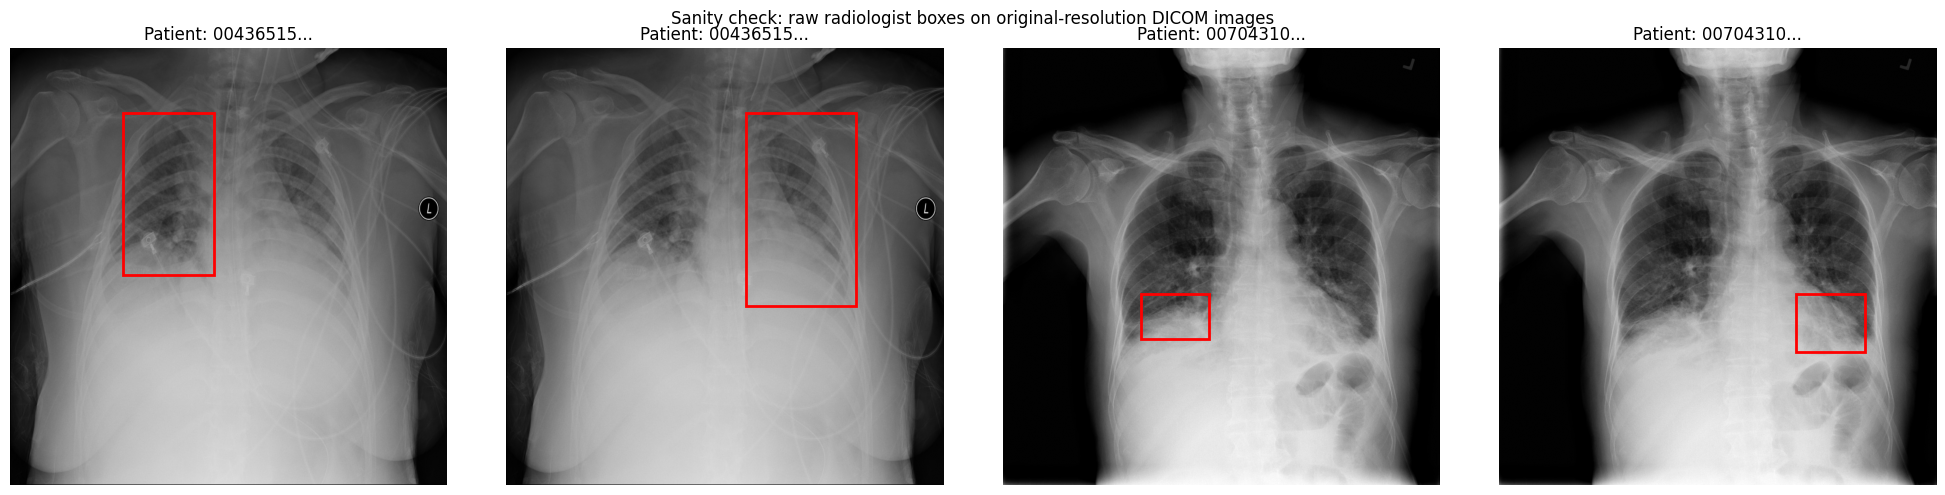

In [ ]:
!pip install pydicom -q
import pydicom, matplotlib.pyplot as plt, matplotlib.patches as patches

# Visual sanity check: plot a few pneumonia-positive images with their RAW
# (un-unioned) bounding boxes, exactly as given in the CSV, to confirm boxes
# land in plausible lung regions before any further processing.
pneumonia_samples = labels_df[labels_df["Target"] == 1].head(4)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for idx, (_, row) in enumerate(pneumonia_samples.iterrows()):
    dicom_path = os.path.join(CONFIG["images_dir"], f"{row['patientId']}.dcm")
    dicom_data = pydicom.dcmread(dicom_path)
    image = dicom_data.pixel_array
    axes[idx].imshow(image, cmap="gray")
    axes[idx].set_title(f"Patient: {row['patientId'][:8]}...")
    rect = patches.Rectangle((row["x"], row["y"]), row["width"], row["height"],
                              linewidth=2, edgecolor="red", facecolor="none")
    axes[idx].add_patch(rect)
    axes[idx].axis("off")
plt.suptitle("Sanity check: raw radiologist boxes on original-resolution DICOM images")
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "sanity_check_boxes.png"), dpi=150)
plt.show()

In [ ]:
sample_path = os.path.join(CONFIG["images_dir"], f"{labels_df['patientId'].iloc[0]}.dcm")
sample_dicom = pydicom.dcmread(sample_path)
print("Image shape:", sample_dicom.pixel_array.shape)
print("Image dtype:", sample_dicom.pixel_array.dtype)
print("Pixel value range:", sample_dicom.pixel_array.min(), "-", sample_dicom.pixel_array.max())
assert sample_dicom.pixel_array.shape == (CONFIG["original_dicom_size"], CONFIG["original_dicom_size"]), \
    "Image size differs from CONFIG['original_dicom_size'] — update the config before continuing."
print("\nAssumption confirmed: images are", CONFIG["original_dicom_size"], "x", CONFIG["original_dicom_size"])

Image shape: (1024, 1024)
Image dtype: uint8
Pixel value range: 0 - 245

Assumption confirmed: images are 1024 x 1024


In [ ]:
# ============================================================
# CANONICAL DICOM LOADING FUNCTION (fixes intensity conversion +
# guarantees model/display/XAI all see the identical pixels)
# ============================================================
import pydicom
import numpy as np
import logging
logging.getLogger("pydicom").setLevel(logging.ERROR)
from PIL import Image

try:
    from pydicom.pixels import apply_voi_lut                    # pydicom >= 3.0 (current)
except ImportError:
    from pydicom.pixel_data_handlers.util import apply_voi_lut  # pydicom < 3.0 (deprecated path)


def load_canonical_pil_image(dicom_path):
    """
    The ONLY function in this notebook that reads pixel data from a .dcm
    file. Handles:
      - RescaleSlope/RescaleIntercept (raw stored values -> real values)
      - VOI LUT / windowing metadata, when present (apply_voi_lut)
      - MONOCHROME1 photometric interpretation (inverted grayscale
        convention vs. the usual MONOCHROME2) -- corrected if present
      - robust min-max normalization to 0-255 uint8, using the array's
        OWN min/max rather than assuming it is already 0-255

    Training data, qualitative display images, and every XAI method's
    model input all call THIS function, so the model, the human-viewed
    image, and the explanation methods can never silently diverge.
    """
    dicom_data = pydicom.dcmread(dicom_path)
    pixel_array = dicom_data.pixel_array.astype(np.float64)

    slope = float(getattr(dicom_data, "RescaleSlope", 1.0))
    intercept = float(getattr(dicom_data, "RescaleIntercept", 0.0))
    pixel_array = pixel_array * slope + intercept

    try:
        pixel_array = apply_voi_lut(pixel_array, dicom_data).astype(np.float64)
    except Exception:
        pass  # no VOI LUT metadata on this file -- fine, min-max below still applies

    photometric = getattr(dicom_data, "PhotometricInterpretation", "MONOCHROME2")
    if photometric == "MONOCHROME1":
        pixel_array = pixel_array.max() - pixel_array

    p_min, p_max = pixel_array.min(), pixel_array.max()
    if p_max > p_min:
        pixel_array = (pixel_array - p_min) / (p_max - p_min) * 255.0
    else:
        pixel_array = np.zeros_like(pixel_array)
    pixel_array = pixel_array.astype(np.uint8)

    return Image.fromarray(pixel_array)  # 2D uint8 array -> Pillow infers mode "L" automatically


def load_canonical_rgb_image(dicom_path):
    """3-channel version (replicated grayscale) for ImageNet-pretrained ResNet-18."""
    return load_canonical_pil_image(dicom_path).convert("RGB")

print("Canonical DICOM loader ready — used by dataset, display, and all XAI code below.")

Canonical DICOM loader ready — used by dataset, display, and all XAI code below.


In [ ]:
# Verification: confirm the canonical loader produces a sane, full-range uint8 image
sample_path = os.path.join(CONFIG["images_dir"], f"{labels_df['patientId'].iloc[0]}.dcm")

_probe = load_canonical_pil_image(sample_path)
_probe_arr = np.array(_probe)

print("Canonical loader output -> mode:", _probe.mode)
print("Canonical loader output -> size (W,H):", _probe.size)
print("Canonical loader output -> dtype:", _probe_arr.dtype)
print("Canonical loader output -> pixel range:", _probe_arr.min(), "-", _probe_arr.max())

assert _probe.mode == "L", "Expected single-channel grayscale mode 'L'"
assert _probe_arr.dtype == np.uint8, "Canonical loader must return uint8"
assert _probe_arr.max() > _probe_arr.min(), "Image appears blank/constant — check DICOM read"
print("\nVerification passed.")

Canonical loader output -> mode: L
Canonical loader output -> size (W,H): (1024, 1024)
Canonical loader output -> dtype: uint8
Canonical loader output -> pixel range: 0 - 255

Verification passed.


In [ ]:
import pydicom
print(pydicom.__version__)

3.0.2


In [ ]:
patient_df = labels_df.groupby("patientId").agg({"Target": "max"}).reset_index()
patient_df["image_path"] = patient_df["patientId"].apply(
    lambda x: os.path.join(CONFIG["images_dir"], f"{x}.dcm")
)
print("Patient-level dataframe:", patient_df.shape)
print(patient_df.head())

# 2) Preserve ALL raw bounding boxes per patient (not collapsed), for later union.
raw_boxes_by_patient = {}
for patient_id, group in labels_df.groupby("patientId"):
    boxes = []
    for _, row in group.iterrows():
        if pd.notna(row["x"]):
            boxes.append((row["x"], row["y"], row["width"], row["height"]))
    raw_boxes_by_patient[patient_id] = boxes  # possibly empty list for Normal patients

n_multi_box = sum(1 for b in raw_boxes_by_patient.values() if len(b) > 1)
print(f"\nPatients with more than one bounding box: {n_multi_box}")
print("These will use the UNION of their boxes as ground truth (Section 14), not a single arbitrarily chosen box.")


Patient-level dataframe: (26684, 3)
                              patientId  Target  \
0  0004cfab-14fd-4e49-80ba-63a80b6bddd6       0   
1  000924cf-0f8d-42bd-9158-1af53881a557       0   
2  000db696-cf54-4385-b10b-6b16fbb3f985       1   
3  000fe35a-2649-43d4-b027-e67796d412e0       1   
4  001031d9-f904-4a23-b3e5-2c088acd19c6       1   

                                          image_path  
0  /content/rsna_data/stage_2_train_images/0004cf...  
1  /content/rsna_data/stage_2_train_images/000924...  
2  /content/rsna_data/stage_2_train_images/000db6...  
3  /content/rsna_data/stage_2_train_images/000fe3...  
4  /content/rsna_data/stage_2_train_images/001031...  

Patients with more than one bounding box: 3398
These will use the UNION of their boxes as ground truth (Section 14), not a single arbitrarily chosen box.


In [ ]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    patient_df,
    test_size=(CONFIG["val_frac"] + CONFIG["test_frac"]),
    stratify=patient_df["Target"],
    random_state=CONFIG["primary_seed"],
)
relative_test_frac = CONFIG["test_frac"] / (CONFIG["val_frac"] + CONFIG["test_frac"])
val_df, test_df = train_test_split(
    temp_df,
    test_size=relative_test_frac,
    stratify=temp_df["Target"],
    random_state=CONFIG["primary_seed"],
)

print("Train size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))



Train size: 18678
Validation size: 4003
Test size: 4003


In [ ]:
import numpy as np

# Class weights computed ONLY from the training split.
# Validation and test labels are not used for training.
class_counts = train_df["Target"].value_counts()
total = len(train_df)

weight_0 = total / (2 * class_counts[0])
weight_1 = total / (2 * class_counts[1])

print("Training patients with No Pneumonia (0):", class_counts[0])
print("Training patients with Pneumonia (1):", class_counts[1])
print(f"Class weight for Normal:    {weight_0:.4f}")
print(f"Class weight for Pneumonia: {weight_1:.4f}")

Training patients with No Pneumonia (0): 14470
Training patients with Pneumonia (1): 4208
Class weight for Normal:    0.6454
Class weight for Pneumonia: 2.2193


In [ ]:
train_ids = set(train_df["patientId"])
val_ids = set(val_df["patientId"])
test_ids = set(test_df["patientId"])

overlap_train_val = train_ids.intersection(val_ids)
overlap_train_test = train_ids.intersection(test_ids)
overlap_val_test = val_ids.intersection(test_ids)

print("Train ∩ Validation overlap:", len(overlap_train_val))
print("Train ∩ Test overlap:      ", len(overlap_train_test))
print("Validation ∩ Test overlap: ", len(overlap_val_test))

assert len(overlap_train_val) == 0, "LEAKAGE: patients appear in both train and validation."
assert len(overlap_train_test) == 0, "LEAKAGE: patients appear in both train and test."
assert len(overlap_val_test) == 0, "LEAKAGE: patients appear in both validation and test."
print("\nAll three leakage checks passed (0 overlap in every pair).")

Train ∩ Validation overlap: 0
Train ∩ Test overlap:       0
Validation ∩ Test overlap:  0

All three leakage checks passed (0 overlap in every pair).


In [ ]:
def class_dist(df, name):
    counts = df["Target"].value_counts().sort_index()
    pct_pneumonia = 100 * counts.get(1, 0) / len(df)
    print(f"{name:12s}: n={len(df):6d}  Normal={counts.get(0,0):6d}  "
          f"Pneumonia={counts.get(1,0):6d}  (%Pneumonia={pct_pneumonia:.1f}%)")

print("Class distribution across splits:")
class_dist(train_df, "Train")
class_dist(val_df, "Validation")
class_dist(test_df, "Test")

Class distribution across splits:
Train       : n= 18678  Normal= 14470  Pneumonia=  4208  (%Pneumonia=22.5%)
Validation  : n=  4003  Normal=  3101  Pneumonia=   902  (%Pneumonia=22.5%)
Test        : n=  4003  Normal=  3101  Pneumonia=   902  (%Pneumonia=22.5%)


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from PIL import Image

class PneumoniaDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        # FIX 2: uses the canonical loader -- identical preprocessing to
        # display and XAI code paths. (Previously this did its own raw
        # pydicom.dcmread + np.stack with no intensity handling.)
        image = load_canonical_rgb_image(row["image_path"])
        label = row["Target"]
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)


train_transform_list = [transforms.Resize((CONFIG["image_size"], CONFIG["image_size"]))]
if CONFIG["use_horizontal_flip"]:
    train_transform_list.append(transforms.RandomHorizontalFlip(p=0.5))
train_transform_list += [
    transforms.ToTensor(),
    transforms.Normalize(mean=CONFIG["imagenet_mean"], std=CONFIG["imagenet_std"]),
]
train_transform = transforms.Compose(train_transform_list)

val_test_transform = transforms.Compose([
    transforms.Resize((CONFIG["image_size"], CONFIG["image_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=CONFIG["imagenet_mean"], std=CONFIG["imagenet_std"]),
])

train_dataset = PneumoniaDataset(train_df, transform=train_transform)
val_dataset = PneumoniaDataset(val_df, transform=val_test_transform)
test_dataset = PneumoniaDataset(test_df, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
                           num_workers=CONFIG["num_workers"])
val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                         num_workers=CONFIG["num_workers"])
test_loader = DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                          num_workers=CONFIG["num_workers"])

print("Dataloaders ready. Training batches:", len(train_loader))
images, labels = next(iter(train_loader))
print("Sanity check batch shape:", images.shape, "| labels sample:", labels[:8].tolist())

Dataloaders ready. Training batches: 584
Sanity check batch shape: torch.Size([32, 3, 224, 224]) | labels sample: [0, 0, 0, 0, 0, 0, 0, 0]


In [ ]:
import torch.nn as nn
import torchvision.models as models
import torch.optim as optim
from sklearn.metrics import roc_auc_score

def build_model():
    model = models.resnet18(weights="IMAGENET1K_V1")
    num_features = model.fc.in_features
    model.fc = nn.Linear(num_features, 2)
    return model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = build_model().to(device)

class_weights_tensor = torch.tensor([weight_0, weight_1], dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
print("Model, loss, optimizer ready.")

Using device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 91.7MB/s]


Model, loss, optimizer ready.


In [ ]:

import time

def evaluate_loader(model, loader, criterion, device):
    """Runs one deterministic pass; returns loss, accuracy, AUC, and raw outputs."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_labels_, all_probs_ = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item()
            probs = torch.softmax(outputs, dim=1)[:, 1]
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
            all_labels_.extend(labels.cpu().numpy())
            all_probs_.extend(probs.cpu().numpy())
    avg_loss = total_loss / len(loader)
    acc = 100 * correct / total
    auc = roc_auc_score(all_labels_, all_probs_)
    return avg_loss, acc, auc, np.array(all_labels_), np.array(all_probs_)


def train_with_early_stopping(model, train_loader, val_loader, criterion, optimizer,
                               device, max_epochs, patience, checkpoint_path):
    """
    Trains up to `max_epochs`, tracking validation ROC-AUC each epoch.
    Saves the best-validation-AUC checkpoint to `checkpoint_path`.
    Stops early if validation AUC has not improved for `patience` epochs.
    Returns the training history and the epoch number of the best model.
    """
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_auc": []}
    best_auc = -1.0
    best_epoch = -1
    epochs_without_improvement = 0

    for epoch in range(max_epochs):
        start_time = time.time()
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        train_loss = running_loss / len(train_loader)

        val_loss, val_acc, val_auc, _, _ = evaluate_loader(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_auc"].append(val_auc)

        elapsed = time.time() - start_time
        improved = val_auc > best_auc
        print(f"Epoch {epoch+1}/{max_epochs} ({elapsed:.1f}s) | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Val Acc: {val_acc:.2f}% | Val AUC: {val_auc:.4f}"
              f"{'  <-- best so far, checkpoint saved' if improved else ''}")

        if improved:
            best_auc = val_auc
            best_epoch = epoch + 1
            epochs_without_improvement = 0
            torch.save(model.state_dict(), checkpoint_path)
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f"\nEarly stopping: no val-AUC improvement for {patience} epochs. "
                      f"Best epoch was {best_epoch} (Val AUC = {best_auc:.4f}).")
                break

    return history, best_epoch, best_auc



In [ ]:
PRIMARY_CHECKPOINT = os.path.join(CONFIG["checkpoint_dir"], f"best_model_seed{CONFIG['primary_seed']}.pth")
history, best_epoch, best_val_auc = train_with_early_stopping(
    model, train_loader, val_loader, criterion, optimizer, device,
    max_epochs=CONFIG["max_epochs"],
    patience=CONFIG["early_stopping_patience"],
    checkpoint_path=PRIMARY_CHECKPOINT,
)
print(f"\nBest epoch: {best_epoch} | Best validation AUC: {best_val_auc:.4f}")
print(f"Best model checkpoint saved to: {PRIMARY_CHECKPOINT}")
# Restore the BEST validation model (not simply the final epoch) for all downstream evaluation.
model.load_state_dict(torch.load(PRIMARY_CHECKPOINT, map_location=device))
model.eval()
print("Best-validation-AUC model restored into `model` for all subsequent evaluation and XAI steps.")

Epoch 1/20 (527.2s) | Train Loss: 0.4974 | Val Loss: 0.4635 | Val Acc: 80.24% | Val AUC: 0.8692  <-- best so far, checkpoint saved
Epoch 2/20 (506.7s) | Train Loss: 0.4372 | Val Loss: 0.4641 | Val Acc: 73.00% | Val AUC: 0.8647
Epoch 3/20 (498.7s) | Train Loss: 0.4175 | Val Loss: 0.4592 | Val Acc: 72.00% | Val AUC: 0.8681
Epoch 4/20 (501.8s) | Train Loss: 0.3826 | Val Loss: 0.4569 | Val Acc: 79.67% | Val AUC: 0.8653
Epoch 5/20 (502.6s) | Train Loss: 0.3515 | Val Loss: 0.4983 | Val Acc: 81.56% | Val AUC: 0.8631
Epoch 6/20 (498.3s) | Train Loss: 0.3132 | Val Loss: 0.5462 | Val Acc: 76.67% | Val AUC: 0.8617

Early stopping: no val-AUC improvement for 5 epochs. Best epoch was 1 (Val AUC = 0.8692).

Best epoch: 1 | Best validation AUC: 0.8692
Best model checkpoint saved to: /content/checkpoints/best_model_seed42.pth
Best-validation-AUC model restored into `model` for all subsequent evaluation and XAI steps.


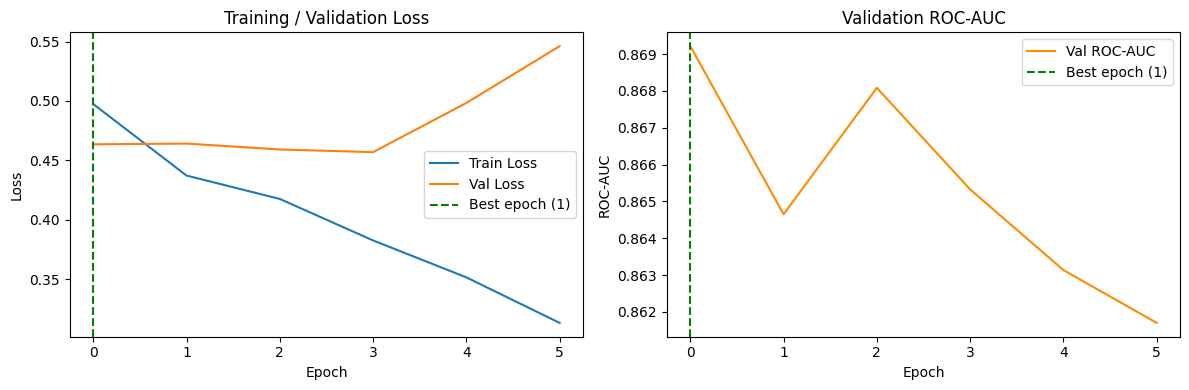

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history["train_loss"], label="Train Loss")
axes[0].plot(history["val_loss"], label="Val Loss")
axes[0].axvline(best_epoch - 1, color="green", linestyle="--", label=f"Best epoch ({best_epoch})")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Training / Validation Loss")
axes[0].legend()
axes[1].plot(history["val_auc"], label="Val ROC-AUC", color="darkorange")
axes[1].axvline(best_epoch - 1, color="green", linestyle="--", label=f"Best epoch ({best_epoch})")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("ROC-AUC"); axes[1].set_title("Validation ROC-AUC")
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "training_curves.png"), dpi=150)
plt.show()

In [ ]:
import json
from sklearn.metrics import roc_curve

_, _, _, val_labels_arr, val_probs_arr = evaluate_loader(model, val_loader, criterion, device)

fpr_val, tpr_val, thresholds_val = roc_curve(val_labels_arr, val_probs_arr)
youden_j = tpr_val - fpr_val
best_idx = int(np.argmax(youden_j))
selected_threshold = float(thresholds_val[best_idx])

CONFIG["classification_threshold"] = selected_threshold
print(f"Selected classification threshold (validation-set Youden's J): {selected_threshold:.4f}")
print(f"  -> Validation sensitivity at this threshold: {tpr_val[best_idx]:.4f}")
print(f"  -> Validation specificity at this threshold: {1 - fpr_val[best_idx]:.4f}")

with open(os.path.join(CONFIG["output_dir"], "config.json"), "w") as f:
    json.dump(CONFIG, f, indent=2)

Selected classification threshold (validation-set Youden's J): 0.3623
  -> Validation sensitivity at this threshold: 0.8282
  -> Validation specificity at this threshold: 0.7456


In [ ]:

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, auc)

_, _, _, test_labels_arr, test_probs_arr = evaluate_loader(model, test_loader, criterion, device)
test_preds_arr = (test_probs_arr >= CONFIG["classification_threshold"]).astype(int)

acc = accuracy_score(test_labels_arr, test_preds_arr)
prec = precision_score(test_labels_arr, test_preds_arr)
rec = recall_score(test_labels_arr, test_preds_arr)          # sensitivity
f1 = f1_score(test_labels_arr, test_preds_arr)
cm = confusion_matrix(test_labels_arr, test_preds_arr)
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)
roc_auc_test = roc_auc_score(test_labels_arr, test_probs_arr)

print(f"Test Accuracy:    {acc:.4f}")
print(f"Test Precision:   {prec:.4f}")
print(f"Test Recall (Sensitivity): {rec:.4f}")
print(f"Test Specificity: {specificity:.4f}")
print(f"Test F1 Score:    {f1:.4f}")
print(f"Test ROC-AUC:     {roc_auc_test:.4f}")
print(f"\nConfusion Matrix counts -> TP={tp}  TN={tn}  FP={fp}  FN={fn}")
print("\nFull classification report:")
print(classification_report(test_labels_arr, test_preds_arr, target_names=["Normal", "Pneumonia"]))

print("""
NOTE ON THE PRECISION/RECALL TRADE-OFF (medical context):
This is a screening-style task where missing a true pneumonia case (a false
negative) is generally considered more costly than a false alarm (a false
positive), since a false negative could delay treatment. The validation-set
Youden's J threshold used here balances sensitivity and specificity rather
than optimizing for precision; a deployment context might justify shifting
the threshold to further favor recall/sensitivity at some cost to precision.
This trade-off should be decided by clinical stakeholders, not by this
notebook.
""")


Test Accuracy:    0.7639
Test Precision:   0.4862
Test Recall (Sensitivity): 0.8392
Test Specificity: 0.7420
Test F1 Score:    0.6157
Test ROC-AUC:     0.8786

Confusion Matrix counts -> TP=757  TN=2301  FP=800  FN=145

Full classification report:
              precision    recall  f1-score   support

      Normal       0.94      0.74      0.83      3101
   Pneumonia       0.49      0.84      0.62       902

    accuracy                           0.76      4003
   macro avg       0.71      0.79      0.72      4003
weighted avg       0.84      0.76      0.78      4003


NOTE ON THE PRECISION/RECALL TRADE-OFF (medical context):
This is a screening-style task where missing a true pneumonia case (a false
negative) is generally considered more costly than a false alarm (a false
positive), since a false negative could delay treatment. The validation-set
Youden's J threshold used here balances sensitivity and specificity rather
than optimizing for precision; a deployment context might justify

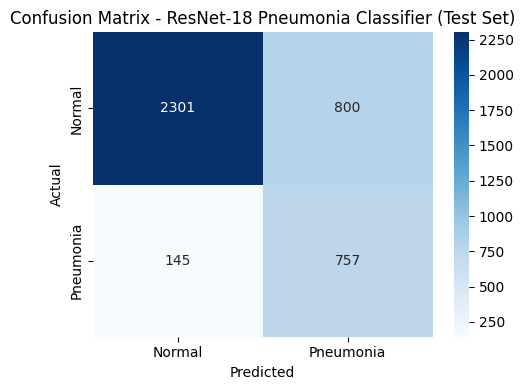

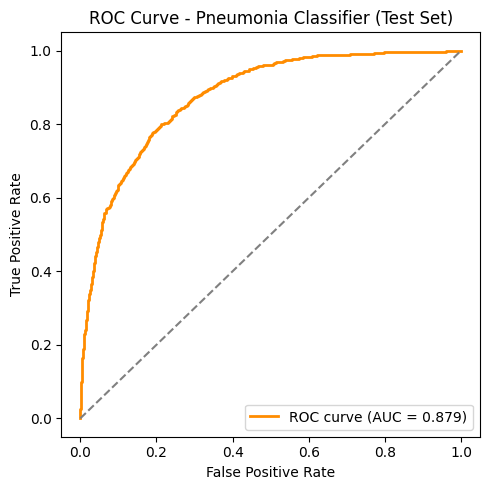

In [ ]:
all_labels = list(test_labels_arr)
all_preds = list(test_preds_arr)
all_probs = list(test_probs_arr)

import seaborn as sns
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Pneumonia"], yticklabels=["Normal", "Pneumonia"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix - ResNet-18 Pneumonia Classifier (Test Set)")
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "confusion_matrix.png"), dpi=150)
plt.show()

fpr, tpr, _ = roc_curve(test_labels_arr, test_probs_arr)
roc_auc_plot = auc(fpr, tpr)
plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc_plot:.3f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Pneumonia Classifier (Test Set)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "roc_curve.png"), dpi=150)
plt.show()

In [ ]:
test_df_reset = test_df.reset_index(drop=True)
assert len(test_df_reset) == len(test_labels_arr), "Row-count mismatch between test_df_reset and predictions."

tp_idx = [i for i in range(len(test_labels_arr)) if test_labels_arr[i] == 1 and test_preds_arr[i] == 1]
fn_idx = [i for i in range(len(test_labels_arr)) if test_labels_arr[i] == 1 and test_preds_arr[i] == 0]
fp_idx = [i for i in range(len(test_labels_arr)) if test_labels_arr[i] == 0 and test_preds_arr[i] == 1]
tn_idx = [i for i in range(len(test_labels_arr)) if test_labels_arr[i] == 0 and test_preds_arr[i] == 0]

print(f"Available in test set -> TP: {len(tp_idx)}  FN: {len(fn_idx)}  FP: {len(fp_idx)}  TN: {len(tn_idx)}")

rng = random.Random(CONFIG["xai_sampling_seed"])

def sample_up_to(pool, n):
    n_actual = min(n, len(pool))
    return rng.sample(pool, n_actual)

sample_tp = sample_up_to(tp_idx, CONFIG["xai_target_tp"])
sample_fn = sample_up_to(fn_idx, CONFIG["xai_target_fn"])
sample_fp = sample_up_to(fp_idx, CONFIG["xai_target_fp"])
sample_tn = sample_up_to(tn_idx, CONFIG["xai_target_tn"])

print(f"Actually sampled -> TP: {len(sample_tp)}  FN: {len(sample_fn)}  FP: {len(sample_fp)}  TN: {len(sample_tn)}")
print("(If any category is smaller than requested, the ACTUAL sampled size above is reported, not the target.)")

xai_sample = (
    [(i, "TP") for i in sample_tp] +
    [(i, "FN") for i in sample_fn] +
    [(i, "FP") for i in sample_fp] +
    [(i, "TN") for i in sample_tn]
)
print(f"\nTotal XAI evaluation sample size: {len(xai_sample)}")

sample_indices = [i for i, _ in xai_sample[:4]]  # kept for quick 4-image qualitative preview below


Available in test set -> TP: 757  FN: 145  FP: 800  TN: 2301
Actually sampled -> TP: 100  FN: 50  FP: 50  TN: 50
(If any category is smaller than requested, the ACTUAL sampled size above is reported, not the target.)

Total XAI evaluation sample size: 250


In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from lime import lime_image
from skimage.segmentation import mark_boundaries
import shap
import torch.nn.functional as F

# ---------- FIX 2: both loaders now share the canonical DICOM path ----------
def load_image_for_display(image_path):
    """Display-only: SAME canonical pixels as the model, resized and scaled 0-1."""
    pil_image = load_canonical_rgb_image(image_path).resize(
        (CONFIG["image_size"], CONFIG["image_size"]))
    return np.array(pil_image).astype(np.float32) / 255.0

def load_input_tensor(image_path):
    """Model input: SAME canonical pixels, deterministic val/test transform applied."""
    pil_image = load_canonical_rgb_image(image_path)
    return val_test_transform(pil_image).unsqueeze(0).to(device)

# ---- Grad-CAM ----
target_layers = [model.layer4[-1]]
gradcam = GradCAM(model=model, target_layers=target_layers)
# targets=None -> pytorch_grad_cam uses the PREDICTED class,
# matching CONFIG["gradcam_explanation_target"] = "predicted_class".

# ---- LIME ----
def lime_predict_fn(images):
    """LIME repeatedly calls this: batch of images (0-255, HWC) -> class probabilities."""
    model.eval()
    batch = []
    for img in images:
        pil_img = Image.fromarray(img.astype(np.uint8))
        tensor_img = val_test_transform(pil_img)
        batch.append(tensor_img)
    batch = torch.stack(batch).to(device)
    with torch.no_grad():
        outputs = model(batch)
        probs = F.softmax(outputs, dim=1)
    return probs.cpu().numpy()

lime_explainer = lime_image.LimeImageExplainer(random_state=CONFIG["primary_seed"])


# ---------- FIX 4: give LIME a real continuous heatmap ----------

def lime_explanation_to_heatmap(explanation, label):
    """
    Converts LIME's superpixel-level weights into a per-pixel heatmap.

    LIME generates explanations at the superpixel level. The superpixel
    weights are projected back to image pixels, producing a piecewise-
    constant heatmap for quantitative comparison.

    Only positive weights are retained, consistent with the qualitative
    LIME visualization.
    """
    segments = explanation.segments
    heatmap = np.zeros(segments.shape, dtype=np.float32)

    for seg_id, weight in explanation.local_exp[label]:
        if weight > 0:
            heatmap[segments == seg_id] = weight

    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()

    return heatmap


def run_lime_explanation(display_image, predicted_label):
    """
    Runs LIME ONCE and returns both representations, so no cell ever pays
    for LIME twice on the same image:
      - lime_overlay : superpixel boundaries, for qualitative figures
      - lime_heatmap : continuous [0,1] heatmap, for quantitative metrics
    """
    lime_input_image = (display_image * 255).astype(np.uint8)
    explanation = lime_explainer.explain_instance(
        lime_input_image, lime_predict_fn, top_labels=2, hide_color=0,
        num_samples=CONFIG["lime_num_samples"]
    )
    temp, lime_mask_topk = explanation.get_image_and_mask(
        label=predicted_label, positive_only=True,
        num_features=CONFIG["lime_num_features"], hide_rest=False
    )
    lime_overlay = mark_boundaries(temp / 255.0, lime_mask_topk)
    lime_heatmap = lime_explanation_to_heatmap(explanation, predicted_label)
    return lime_overlay, lime_heatmap


# ---- SHAP ----
# Background sampled ONLY from the training set (never validation/test).
shap_rng = np.random.RandomState(CONFIG["primary_seed"])
background_indices = shap_rng.choice(len(train_dataset), CONFIG["shap_background_size"], replace=False)
background_images = torch.stack([train_dataset[i][0] for i in background_indices]).to(device)
shap_explainer = shap.GradientExplainer(model, background_images)
# CHANNEL REDUCTION: the 3 channels are duplicated copies of one grayscale
# X-ray, so channel-wise sign differences carry no information; we sum the
# ABSOLUTE attribution across channels to get total magnitude per pixel.

def get_shap_heatmap(input_tensor, predicted_label):
    """
    Generates a SHAP heatmap for the SAME class predicted by the model.

    predicted_label:
        0 = Normal
        1 = Pneumonia

    This ensures SHAP, Grad-CAM, and LIME explain the same predicted class.
    """
    shap_values = shap_explainer.shap_values(input_tensor)

    if isinstance(shap_values, list):
        # Older SHAP API:
        # [class][image, channel, height, width]
        class_shap = shap_values[predicted_label][0]

    else:
        # Newer SHAP API:
        # [image, channel, height, width, class]
        class_shap = shap_values[0, :, :, :, predicted_label]

    # Sum absolute attribution across the duplicated RGB channels.
    heatmap = np.abs(class_shap).sum(axis=0)

    # Normalize to [0, 1].
    heatmap = (
        heatmap - heatmap.min()
    ) / (
        heatmap.max() - heatmap.min() + 1e-8
    )

    return heatmap

print("Grad-CAM, LIME (with continuous heatmap), SHAP explainers initialized.")

Grad-CAM, LIME (with continuous heatmap), SHAP explainers initialized.


In [ ]:
import matplotlib.patches as patches

def get_union_gt_mask(patient_id, raw_boxes_by_patient, original_size, resized_size, image_size=None):
    """
    Builds the ground-truth region as the UNION of ALL of this patient's
    radiologist bounding boxes (not a single arbitrarily-chosen box),
    rescaled from the original DICOM resolution to the model's input
    resolution, returned as a binary mask.
    """
    if image_size is None:
        image_size = resized_size
    scale = resized_size / original_size
    mask = np.zeros((image_size, image_size), dtype=np.uint8)
    for (x, y, w, h) in raw_boxes_by_patient.get(patient_id, []):
        x1, y1 = int(x * scale), int(y * scale)
        x2, y2 = int((x + w) * scale), int((y + h) * scale)
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(image_size, x2), min(image_size, y2)
        mask[y1:y2, x1:x2] = 1   # union: OR-combine all boxes via simple max-assignment
    return mask

def draw_mask_boundary(ax, mask, color="lime"):
    """Draws the boundary of a binary union mask (may be one or more disjoint boxes)."""
    ax.contour(mask, levels=[0.5], colors=[color], linewidths=2)

print("Union ground-truth mask builder ready.")


Union ground-truth mask builder ready.


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

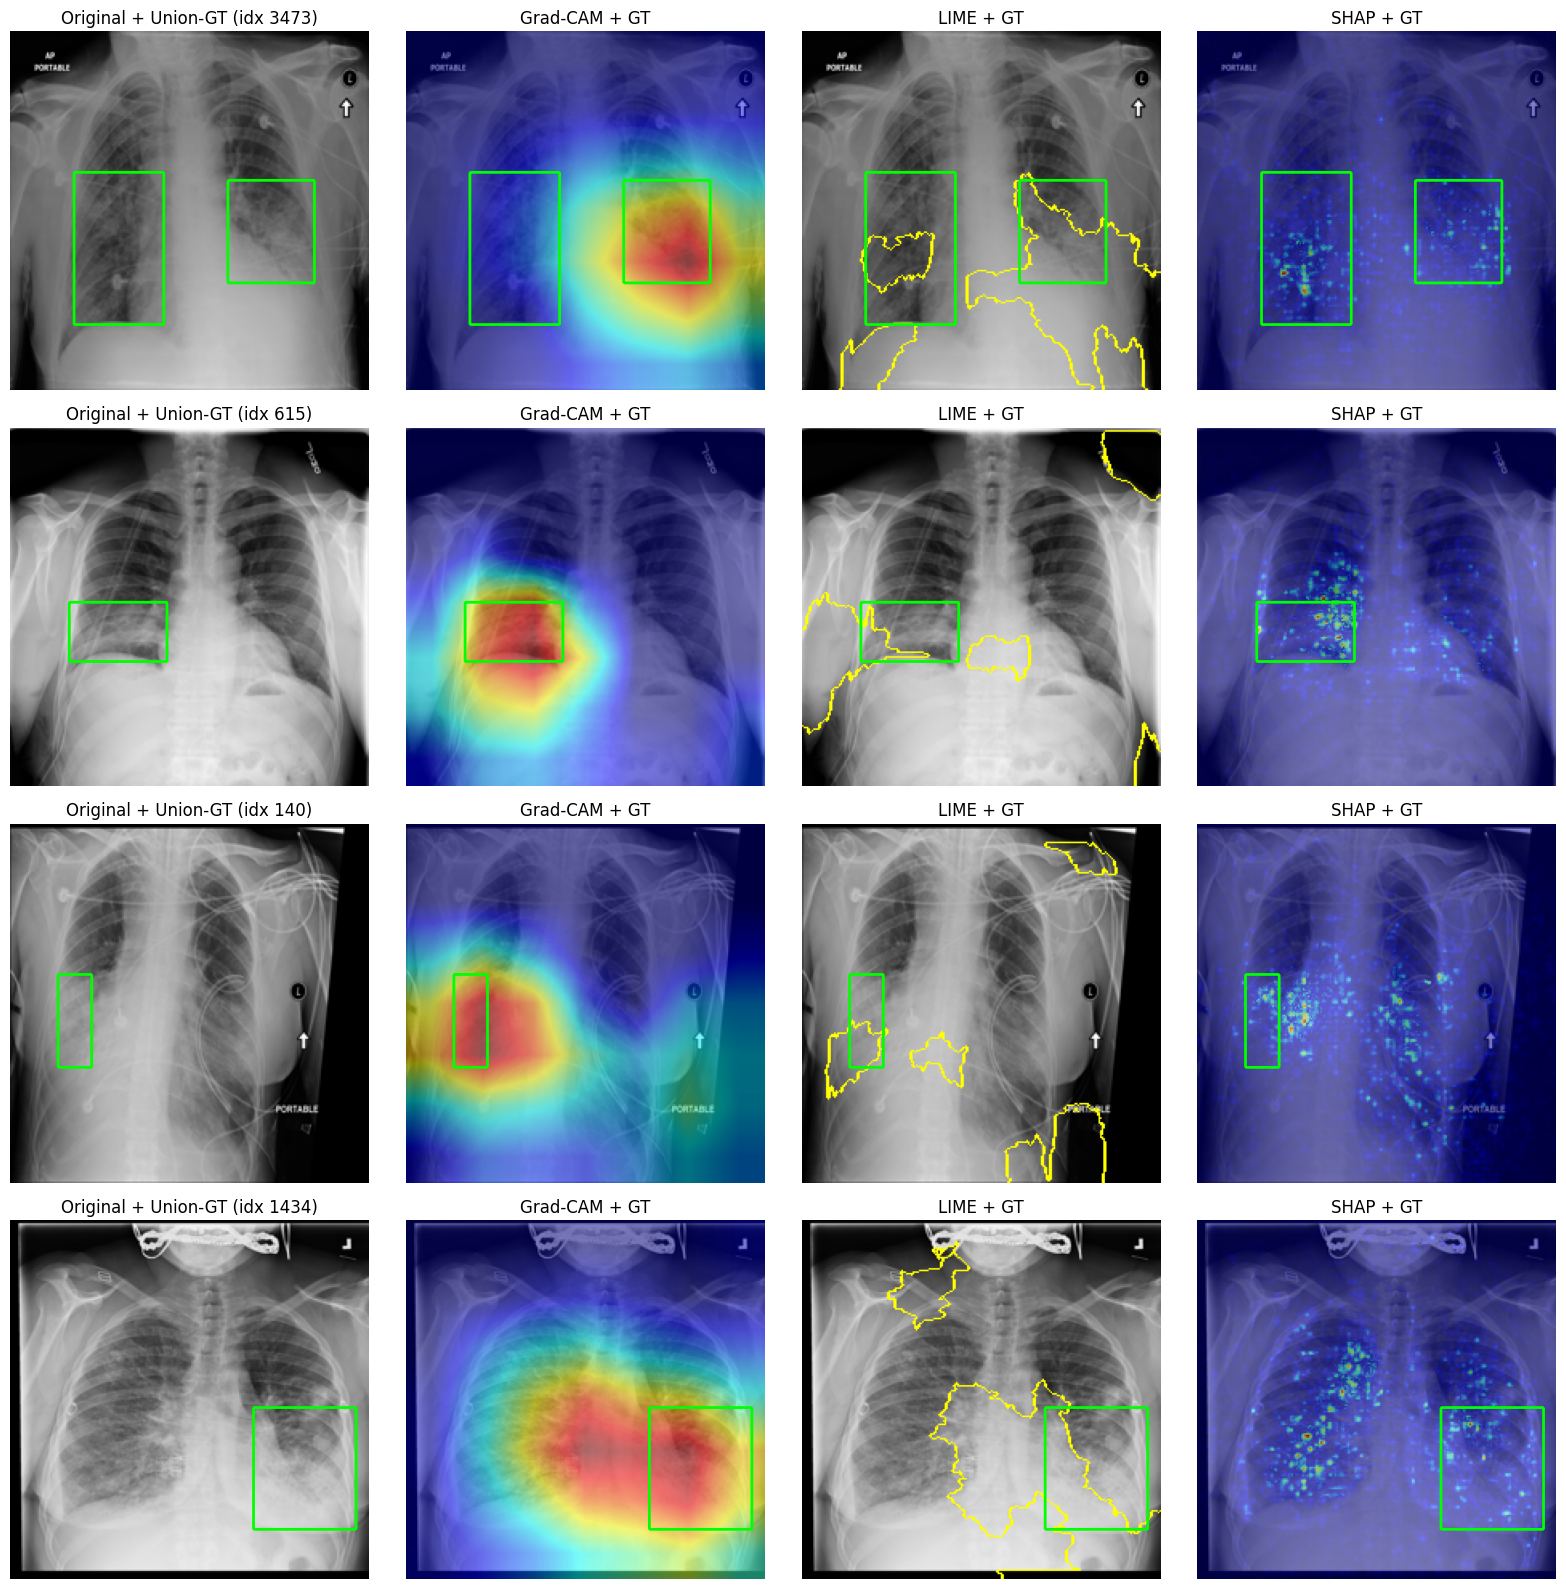

In [ ]:
preview_indices = sample_indices  # first 4 from the stratified sample (mixed TP/FN/FP/TN order)

fig, axes = plt.subplots(len(preview_indices), 4, figsize=(16, 4 * len(preview_indices)))
if len(preview_indices) == 1:
    axes = axes.reshape(1, -1)

for row, idx in enumerate(preview_indices):
    image_path = test_df_reset.iloc[idx]["image_path"]
    patient_id = test_df_reset.iloc[idx]["patientId"]
    display_image = load_image_for_display(image_path)
    input_tensor = load_input_tensor(image_path)
    predicted_label = int(test_preds_arr[idx])
    gt_mask = get_union_gt_mask(patient_id, raw_boxes_by_patient,
                                 CONFIG["original_dicom_size"], CONFIG["image_size"])

    grayscale_cam = gradcam(input_tensor=input_tensor,targets=[ClassifierOutputTarget(predicted_label)]
)[0]
    cam_image = show_cam_on_image(display_image, grayscale_cam, use_rgb=True)

    lime_overlay, _ = run_lime_explanation(display_image, predicted_label)   # FIX 4

    shap_heatmap = get_shap_heatmap(
    input_tensor,
    predicted_label
    )
    axes[row, 0].imshow(display_image)
    draw_mask_boundary(axes[row, 0], gt_mask)
    axes[row, 0].set_title(f"Original + Union-GT (idx {idx})"); axes[row, 0].axis("off")

    axes[row, 1].imshow(cam_image)
    draw_mask_boundary(axes[row, 1], gt_mask)
    axes[row, 1].set_title("Grad-CAM + GT"); axes[row, 1].axis("off")

    axes[row, 2].imshow(lime_overlay)
    draw_mask_boundary(axes[row, 2], gt_mask)
    axes[row, 2].set_title("LIME + GT"); axes[row, 2].axis("off")

    axes[row, 3].imshow(display_image)
    axes[row, 3].imshow(shap_heatmap, cmap="jet", alpha=0.5)
    draw_mask_boundary(axes[row, 3], gt_mask)
    axes[row, 3].set_title("SHAP + GT"); axes[row, 3].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "xai_qualitative_grid.png"), dpi=150)
plt.show()

Safe top-k tests passed (exact count, ties, NaN, constant map).
Validation XAI threshold-development sample: 50 pneumonia-positive images.
top  2% -> Grad-CAM mean IoU: 0.0791 | SHAP mean IoU: 0.0819 | joint: 0.0805
top  5% -> Grad-CAM mean IoU: 0.1588 | SHAP mean IoU: 0.1470 | joint: 0.1529
top 10% -> Grad-CAM mean IoU: 0.2068 | SHAP mean IoU: 0.1986 | joint: 0.2027
top 15% -> Grad-CAM mean IoU: 0.2275 | SHAP mean IoU: 0.2206 | joint: 0.2241
top 20% -> Grad-CAM mean IoU: 0.2366 | SHAP mean IoU: 0.2285 | joint: 0.2326
top 30% -> Grad-CAM mean IoU: 0.2384 | SHAP mean IoU: 0.2266 | joint: 0.2325

Selected validation-derived top-percent value: top 20%


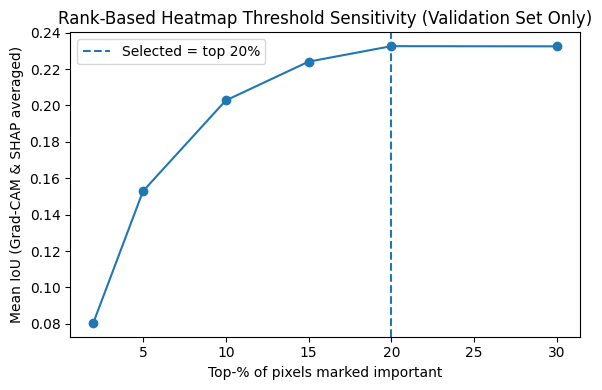

Frozen XAI threshold configuration saved.


In [ ]:
# ============================================================
# RANK-BASED HEATMAP THRESHOLDING
#
# Selects exactly the requested top-% of pixels from an XAI heatmap.
# The threshold-development percentage is selected using VALIDATION
# data only and then frozen before TEST evaluation.
# ============================================================

import numpy as np
import random
import json


def heatmap_to_mask_percentile(heatmap, top_percent, tiebreak_seed=0):
    """
    Select exactly k = ceil(N * top_percent / 100) pixels.

    Handling:
      - NaN / +/-inf values are never preferred over finite values.
      - Ties are broken deterministically using a seeded random key.
      - Constant heatmaps still return exactly k pixels.
    """

    h = np.asarray(heatmap, dtype=np.float64)

    if not (0 < top_percent <= 100):
        raise ValueError(
            f"top_percent must be in (0, 100], got {top_percent}"
        )

    n = h.size

    k = min(
        n,
        max(
            1,
            int(np.ceil(n * top_percent / 100.0))
        )
    )

    flat = h.ravel().copy()

    finite = np.isfinite(flat)

    if finite.any():

        # Put non-finite values below every finite value.
        flat[~finite] = flat[finite].min() - 1.0

    else:

        # Entire heatmap is invalid.
        flat[:] = 0.0

    # Deterministic tie-breaking.
    tie_key = np.random.default_rng(
        tiebreak_seed
    ).random(n)

    # Primary sort: heatmap value descending.
    # Secondary sort: deterministic random key.
    order = np.lexsort(
        (tie_key, -flat)
    )

    mask = np.zeros(
        n,
        dtype=np.uint8
    )

    mask[order[:k]] = 1

    return mask.reshape(h.shape)


# ============================================================
# SELF-TESTS
# ============================================================

_t = np.arange(
    100,
    dtype=np.float32
).reshape(10, 10)

assert (
    heatmap_to_mask_percentile(_t, 10).sum()
    == 10
)

assert (
    heatmap_to_mask_percentile(_t, 10)[9].sum()
    == 10
)


# Test tied heatmap
_ties = np.ones(
    (224, 224),
    dtype=np.float32
)

_m = heatmap_to_mask_percentile(
    _ties,
    10
)

assert (
    _m.sum()
    == int(np.ceil(224 * 224 * 10 / 100))
)

assert np.where(_m)[0].max() > 150


# Test NaN handling
_nan = np.random.rand(
    224,
    224
).astype(np.float32)

_nan[0, :20] = np.nan

_m = heatmap_to_mask_percentile(
    _nan,
    5
)

assert (
    _m.sum()
    == int(np.ceil(224 * 224 * 5 / 100))
)

assert (
    _m[0, :20].sum()
    == 0
)


# Test constant heatmap
assert (
    heatmap_to_mask_percentile(
        np.zeros((224, 224)),
        5
    ).sum()
    == int(np.ceil(224 * 224 * 5 / 100))
)

print(
    "Safe top-k tests passed "
    "(exact count, ties, NaN, constant map)."
)


# ============================================================
# IoU
# ============================================================

def iou_score(mask1, mask2):

    intersection = np.logical_and(
        mask1,
        mask2
    ).sum()

    union = np.logical_or(
        mask1,
        mask2
    ).sum()

    return (
        0.0
        if union == 0
        else intersection / union
    )


# ============================================================
# XAI TOP-% DEVELOPMENT
#
# IMPORTANT:
# The top-% value is selected ONLY from validation data.
#
# We use up to 50 pneumonia-positive validation images.
# The selected value is frozen before test-set evaluation.
#
# Grad-CAM and SHAP are used for threshold development.
# LIME receives the same frozen top-% during final evaluation.
# ============================================================

val_df_reset = val_df.reset_index(
    drop=True
)


val_pneumonia_idx = [
    i
    for i in range(len(val_df_reset))
    if val_df_reset.iloc[i]["Target"] == 1
]


dev_rng = random.Random(
    CONFIG["primary_seed"]
)


dev_sample_size = min(
    50,
    len(val_pneumonia_idx)
)


dev_sample = dev_rng.sample(
    val_pneumonia_idx,
    dev_sample_size
)


print(
    f"Validation XAI threshold-development sample: "
    f"{len(dev_sample)} pneumonia-positive images."
)


percent_grid = CONFIG[
    "heatmap_top_percent_grid"
]


threshold_results = {
    p: {
        "GradCAM": [],
        "SHAP": []
    }
    for p in percent_grid
}


# ============================================================
# RUN VALIDATION THRESHOLD DEVELOPMENT
# ============================================================

for idx in dev_sample:

    image_path = val_df_reset.iloc[
        idx
    ]["image_path"]

    patient_id = val_df_reset.iloc[
        idx
    ]["patientId"]


    input_tensor = load_input_tensor(
        image_path
    )


    # --------------------------------------------------------
    # Determine the model's predicted class.
    # Grad-CAM and SHAP explain this SAME predicted class.
    # --------------------------------------------------------

    with torch.no_grad():

        outputs = model(
            input_tensor
        )

        prob_pneu = torch.softmax(
            outputs,
            dim=1
        )[0, 1].item()

        predicted_label = int(
            prob_pneu
            >= CONFIG["classification_threshold"]
        )


    # --------------------------------------------------------
    # Ground-truth localization mask
    # --------------------------------------------------------

    gt_mask = get_union_gt_mask(
        patient_id,
        raw_boxes_by_patient,
        CONFIG["original_dicom_size"],
        CONFIG["image_size"]
    )


    # Skip images without localization ground truth.
    if gt_mask.sum() == 0:
        continue


    # ========================================================
    # Grad-CAM
    # ========================================================

    cam_dev = gradcam(
        input_tensor=input_tensor,
        targets=[
            ClassifierOutputTarget(
                predicted_label
            )
        ]
    )[0]


    # ========================================================
    # SHAP
    # ========================================================

    shap_dev = get_shap_heatmap(
        input_tensor,
        predicted_label
    )


    # ========================================================
    # Evaluate every candidate top-% value
    # ========================================================

    for p in percent_grid:

        threshold_results[p][
            "GradCAM"
        ].append(
            iou_score(
                heatmap_to_mask_percentile(
                    cam_dev,
                    p
                ),
                gt_mask
            )
        )


        threshold_results[p][
            "SHAP"
        ].append(
            iou_score(
                heatmap_to_mask_percentile(
                    shap_dev,
                    p
                ),
                gt_mask
            )
        )


# ============================================================
# SELECT BEST TOP-% USING VALIDATION DATA ONLY
# ============================================================

mean_combined_by_percent = {}


for p in percent_grid:

    gc_mean = (
        np.mean(
            threshold_results[p]["GradCAM"]
        )
        if threshold_results[p]["GradCAM"]
        else 0.0
    )


    sh_mean = (
        np.mean(
            threshold_results[p]["SHAP"]
        )
        if threshold_results[p]["SHAP"]
        else 0.0
    )


    mean_combined_by_percent[p] = (
        gc_mean + sh_mean
    ) / 2.0


    print(
        f"top {p:>2}% -> "
        f"Grad-CAM mean IoU: {gc_mean:.4f} | "
        f"SHAP mean IoU: {sh_mean:.4f} | "
        f"joint: {mean_combined_by_percent[p]:.4f}"
    )


best_percent = max(
    mean_combined_by_percent,
    key=mean_combined_by_percent.get
)


CONFIG[
    "heatmap_top_percent_final"
] = float(
    best_percent
)


print(
    f"\nSelected validation-derived "
    f"top-percent value: top {best_percent}%"
)


# ============================================================
# THRESHOLD SENSITIVITY PLOT
# ============================================================

plt.figure(
    figsize=(6, 4)
)


plt.plot(
    percent_grid,
    [
        mean_combined_by_percent[p]
        for p in percent_grid
    ],
    marker="o"
)


plt.axvline(
    best_percent,
    linestyle="--",
    label=f"Selected = top {best_percent}%"
)


plt.xlabel(
    "Top-% of pixels marked important"
)

plt.ylabel(
    "Mean IoU (Grad-CAM & SHAP averaged)"
)

plt.title(
    "Rank-Based Heatmap Threshold Sensitivity "
    "(Validation Set Only)"
)


plt.legend()

plt.tight_layout()


plt.savefig(
    os.path.join(
        CONFIG["output_dir"],
        "threshold_sensitivity.png"
    ),
    dpi=150
)


plt.show()


# ============================================================
# SAVE FROZEN CONFIGURATION
# ============================================================

with open(
    os.path.join(
        CONFIG["output_dir"],
        "config.json"
    ),
    "w"
) as f:

    json.dump(
        CONFIG,
        f,
        indent=2
    )


print(
    "Frozen XAI threshold configuration saved."
)

In [ ]:
def dice_score(mask1, mask2):
    inter = np.logical_and(mask1, mask2).sum()
    denom = mask1.sum() + mask2.sum()
    return 0.0 if denom == 0 else (2.0 * inter) / denom

def pointing_game_hit(heatmap, gt_mask):
    if gt_mask.sum() == 0:
        return np.nan
    y, x = np.unravel_index(np.argmax(heatmap), heatmap.shape)
    return 1.0 if gt_mask[y, x] == 1 else 0.0

def coverage_score(pred_mask, gt_mask):
    if gt_mask.sum() == 0:
        return np.nan
    inter = np.logical_and(pred_mask, gt_mask).sum()
    return inter / gt_mask.sum()

def precision_score_region(pred_mask, gt_mask):
    if pred_mask.sum() == 0:
        return np.nan
    inter = np.logical_and(pred_mask, gt_mask).sum()
    return inter / pred_mask.sum()

def lime_mask_to_binary(lime_mask_raw):
    return (lime_mask_raw > 0).astype(np.uint8)

print("Metric functions ready: IoU, Dice, Pointing-Game, Coverage, Precision.")

Metric functions ready: IoU, Dice, Pointing-Game, Coverage, Precision.


In [ ]:
# =============================================================
# FULL XAI EVALUATION
# Grad-CAM + LIME + SHAP
# =============================================================

# -------------------------------------------------------------
# Required Grad-CAM target import
# -------------------------------------------------------------
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("ClassifierOutputTarget imported successfully.")


# -------------------------------------------------------------
# Configuration
# -------------------------------------------------------------
top_percent = CONFIG["heatmap_top_percent_final"]

results = []
skipped_empty_gt = 0

print(
    f"Running full XAI evaluation over {len(xai_sample)} images "
    f"at top-{top_percent}% threshold (slow step, mainly LIME)..."
)


# =============================================================
# Process every XAI evaluation image
# =============================================================

for i, (idx, outcome) in enumerate(xai_sample):

    image_path = test_df_reset.iloc[idx]["image_path"]
    patient_id = test_df_reset.iloc[idx]["patientId"]

    # ---------------------------------------------------------
    # Load canonical image
    # ---------------------------------------------------------
    input_tensor = load_input_tensor(image_path)
    display_image = load_image_for_display(image_path)

    # ---------------------------------------------------------
    # Classification prediction
    # ---------------------------------------------------------
    # IMPORTANT:
    # This prediction uses the frozen validation-selected
    # classification threshold.
    predicted_label = int(test_preds_arr[idx])

    assert predicted_label in (0, 1), (
        f"Invalid predicted label: {predicted_label}"
    )

    # ---------------------------------------------------------
    # Ground-truth mask
    # ---------------------------------------------------------
    gt_mask = get_union_gt_mask(
        patient_id,
        raw_boxes_by_patient,
        CONFIG["original_dicom_size"],
        CONFIG["image_size"]
    )

    has_gt = gt_mask.sum() > 0

    if not has_gt:
        skipped_empty_gt += 1

    # =========================================================
    # Grad-CAM
    # =========================================================

    # Explicitly explain the SAME predicted class that is used
    # for LIME and SHAP.
    grayscale_cam = gradcam(
        input_tensor=input_tensor,
        targets=[
            ClassifierOutputTarget(predicted_label)
        ]
    )[0]

    gradcam_mask = heatmap_to_mask_percentile(
        grayscale_cam,
        top_percent
    )

    # =========================================================
    # SHAP
    # =========================================================

    # Explain the SAME predicted class.
    shap_heatmap = get_shap_heatmap(
        input_tensor,
        predicted_label
    )

    shap_mask = heatmap_to_mask_percentile(
        shap_heatmap,
        top_percent
    )

    # =========================================================
    # LIME
    # =========================================================

    # LIME explains the SAME predicted class.
    #
    # LIME is generated at the superpixel level and projected
    # back to pixels as a piecewise-constant heatmap.
    lime_overlay, lime_heatmap = run_lime_explanation(
        display_image,
        predicted_label
    )

    lime_mask = heatmap_to_mask_percentile(
        lime_heatmap,
        top_percent
    )

    # =========================================================
    # Sanity checks
    # =========================================================

    assert predicted_label in (0, 1), (
        f"Invalid predicted label: {predicted_label}"
    )

    # ---------------------------------------------------------
    # Heatmap dimensions
    # ---------------------------------------------------------

    assert grayscale_cam.shape == (
        CONFIG["image_size"],
        CONFIG["image_size"]
    ), (
        f"Unexpected Grad-CAM shape: {grayscale_cam.shape}"
    )

    assert shap_heatmap.shape == (
        CONFIG["image_size"],
        CONFIG["image_size"]
    ), (
        f"Unexpected SHAP shape: {shap_heatmap.shape}"
    )

    assert lime_heatmap.shape == (
        CONFIG["image_size"],
        CONFIG["image_size"]
    ), (
        f"Unexpected LIME shape: {lime_heatmap.shape}"
    )

    # ---------------------------------------------------------
    # Finite-value checks
    # ---------------------------------------------------------

    assert np.isfinite(grayscale_cam).all(), (
        "Grad-CAM contains non-finite values."
    )

    assert np.isfinite(shap_heatmap).all(), (
        "SHAP heatmap contains non-finite values."
    )

    assert np.isfinite(lime_heatmap).all(), (
        "LIME heatmap contains non-finite values."
    )

    # =========================================================
    # Heatmap range checks
    # =========================================================

    assert grayscale_cam.min() >= -1e-6, (
        "Grad-CAM contains values below 0."
    )

    assert grayscale_cam.max() <= 1.0 + 1e-6, (
        "Grad-CAM contains values above 1."
    )

    assert shap_heatmap.min() >= -1e-6, (
        "SHAP heatmap contains values below 0."
    )

    assert shap_heatmap.max() <= 1.0 + 1e-6, (
        "SHAP heatmap contains values above 1."
    )

    assert lime_heatmap.min() >= -1e-6, (
        "LIME heatmap contains values below 0."
    )

    assert lime_heatmap.max() <= 1.0 + 1e-6, (
        "LIME heatmap contains values above 1."
    )

    # =========================================================
    # Binary mask checks
    # =========================================================

    assert set(
        np.unique(gradcam_mask)
    ).issubset({0, 1}), (
        "Grad-CAM mask contains values other than 0/1."
    )

    assert set(
        np.unique(shap_mask)
    ).issubset({0, 1}), (
        "SHAP mask contains values other than 0/1."
    )

    assert set(
        np.unique(lime_mask)
    ).issubset({0, 1}), (
        "LIME mask contains values other than 0/1."
    )

    # =========================================================
    # Exact top-k pixel count
    # =========================================================

    expected_selected_pixels = int(
        np.ceil(
            CONFIG["image_size"]
            * CONFIG["image_size"]
            * top_percent
            / 100.0
        )
    )

    for method_name, pred_mask in [
        ("GradCAM", gradcam_mask),
        ("SHAP", shap_mask),
        ("LIME", lime_mask),
    ]:

        actual_selected_pixels = int(
            pred_mask.sum()
        )

        assert actual_selected_pixels == expected_selected_pixels, (
            f"{method_name} mask selected "
            f"{actual_selected_pixels} pixels, expected "
            f"{expected_selected_pixels} for top-{top_percent}%."
        )

    # =========================================================
    # Store basic information
    # =========================================================

    row = {
        "idx": idx,
        "outcome": outcome,
        "has_gt": has_gt,
        "predicted_label": predicted_label,

        # All three methods explicitly explain the same class
        "GradCAM_target_class": predicted_label,
        "LIME_target_class": predicted_label,
        "SHAP_target_class": predicted_label,
    }

    # =========================================================
    # Localization metrics
    # =========================================================

    for method_name, heatmap_arr, pred_mask in [
        ("GradCAM", grayscale_cam, gradcam_mask),
        ("LIME", lime_heatmap, lime_mask),
        ("SHAP", shap_heatmap, shap_mask),
    ]:

        if has_gt:

            # -------------------------------------------------
            # IoU
            # -------------------------------------------------
            row[
                f"IoU_{method_name}"
            ] = iou_score(
                pred_mask,
                gt_mask
            )

            # -------------------------------------------------
            # Dice
            # -------------------------------------------------
            row[
                f"Dice_{method_name}"
            ] = dice_score(
                pred_mask,
                gt_mask
            )

            # -------------------------------------------------
            # Coverage
            # -------------------------------------------------
            row[
                f"Coverage_{method_name}"
            ] = coverage_score(
                pred_mask,
                gt_mask
            )

            # -------------------------------------------------
            # Precision
            # -------------------------------------------------
            row[
                f"Precision_{method_name}"
            ] = precision_score_region(
                pred_mask,
                gt_mask
            )

            # -------------------------------------------------
            # Pointing Game
            # -------------------------------------------------
            if method_name == "LIME":

                # LIME is superpixel-based. Its projected heatmap
                # may contain tied maximum values, so Pointing
                # Game is not defined for this evaluation.
                row[
                    f"PointingGame_{method_name}"
                ] = np.nan

            else:

                row[
                    f"PointingGame_{method_name}"
                ] = pointing_game_hit(
                    heatmap_arr,
                    gt_mask
                )

        else:

            # No radiologist annotation available.
            # Localization metrics are therefore undefined.
            for metric in [
                "IoU",
                "Dice",
                "Coverage",
                "Precision",
                "PointingGame"
            ]:

                row[
                    f"{metric}_{method_name}"
                ] = np.nan

    # ---------------------------------------------------------
    # Add this image's result
    # ---------------------------------------------------------
    results.append(row)

    # ---------------------------------------------------------
    # Progress
    # ---------------------------------------------------------
    if (i + 1) % 25 == 0:

        print(
            f"Processed {i + 1}/{len(xai_sample)} images..."
        )


# =============================================================
# Create complete XAI results DataFrame
# =============================================================

xai_results_df = pd.DataFrame(results)


# =============================================================
# Save results
# =============================================================

xai_results_path = os.path.join(
    CONFIG["output_dir"],
    "xai_results_full.csv"
)

xai_results_df.to_csv(
    xai_results_path,
    index=False
)


# =============================================================
# Final summary
# =============================================================

print(
    f"\nDone. Skipped (empty ground truth, e.g. True Negatives): "
    f"{skipped_empty_gt}"
)

print(
    f"Rows with valid ground truth used for overlap metrics: "
    f"{xai_results_df['has_gt'].sum()}"
)

print(
    f"Total XAI evaluation rows: "
    f"{len(xai_results_df)}"
)

print(
    f"Frozen XAI threshold used: "
    f"top-{top_percent}%"
)

print(
    f"Saved XAI results to:\n{xai_results_path}"
)


# =============================================================
# Display results preview
# =============================================================

pd.set_option(
    "display.max_columns",
    None
)

print("\nXAI results preview:")

display(
    xai_results_df.head()
)


# =============================================================
# Expected columns
# =============================================================

expected_xai_columns = [

    "idx",
    "outcome",
    "has_gt",
    "predicted_label",

    "GradCAM_target_class",
    "LIME_target_class",
    "SHAP_target_class",

    "IoU_GradCAM",
    "Dice_GradCAM",
    "Coverage_GradCAM",
    "Precision_GradCAM",
    "PointingGame_GradCAM",

    "IoU_LIME",
    "Dice_LIME",
    "Coverage_LIME",
    "Precision_LIME",
    "PointingGame_LIME",

    "IoU_SHAP",
    "Dice_SHAP",
    "Coverage_SHAP",
    "Precision_SHAP",
    "PointingGame_SHAP",
]


missing_columns = [
    col
    for col in expected_xai_columns
    if col not in xai_results_df.columns
]


assert not missing_columns, (
    f"Missing expected XAI result columns: "
    f"{missing_columns}"
)


print(
    "\nAll expected XAI result columns are present."
)


# =============================================================
# Verify explanation-target consistency
# =============================================================

assert (
    xai_results_df["GradCAM_target_class"]
    ==
    xai_results_df["predicted_label"]
).all()


assert (
    xai_results_df["LIME_target_class"]
    ==
    xai_results_df["predicted_label"]
).all()


assert (
    xai_results_df["SHAP_target_class"]
    ==
    xai_results_df["predicted_label"]
).all()


print(
    "Explanation-target consistency check passed: "
    "Grad-CAM, LIME, and SHAP use the same predicted class."
)

ClassifierOutputTarget imported successfully.
Running full XAI evaluation over 250 images at top-20.0% threshold (slow step, mainly LIME)...


  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

...

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

Processed 250/250 images...

Done. Skipped (empty ground truth, e.g. True Negatives): 100
Rows with valid ground truth used for overlap metrics: 150
Total XAI evaluation rows: 250
Frozen XAI threshold used: top-20.0%
Saved XAI results to:
/content/results/xai_results_full.csv

XAI results preview:


,idx,outcome,has_gt,predicted_label,GradCAM_target_class,LIME_target_class,SHAP_target_class,IoU_GradCAM,Dice_GradCAM,Coverage_GradCAM,Precision_GradCAM,PointingGame_GradCAM,IoU_LIME,Dice_LIME,Coverage_LIME,Precision_LIME,PointingGame_LIME,IoU_SHAP,Dice_SHAP,Coverage_SHAP,Precision_SHAP,PointingGame_SHAP
0,3473,TP,True,1,1,1,1,0.223226,0.364980,0.391180,0.342069,1.0,0.183070,0.309483,0.331700,0.290056,NaN,0.488056,0.655964,0.703054,0.614787,1.0
1,615,TP,True,1,1,1,1,0.224890,0.367201,1.000000,0.224890,1.0,0.042486,0.081510,0.221976,0.049920,NaN,0.162349,0.279346,0.760744,0.171084,1.0
2,140,TP,True,1,1,1,1,0.121363,0.216456,1.000000,0.121363,1.0,0.042616,0.081749,0.377668,0.045835,NaN,0.063203,0.118891,0.549261,0.066660,0.0
3,1434,TP,True,1,1,1,1,0.362597,0.532215,0.815173,0.395078,0.0,0.167163,0.286443,0.438734,0.212635,NaN,0.194772,0.326040,0.499383,0.242029,0.0
4,1267,TP,True,1,1,1,1,0.104922,0.189918,1.000000,0.104922,0.0,0.000000,0.000000,0.000000,0.000000,NaN,0.061961,0.116692,0.614435,0.064468,0.0



All expected XAI result columns are present.
Explanation-target consistency check passed: Grad-CAM, LIME, and SHAP use the same predicted class.


In [ ]:
metrics = [
    "IoU",
    "Dice",
    "Coverage",
    "Precision"
]

methods = [
    "GradCAM",
    "LIME",
    "SHAP"
]

summary_rows = []

gt_subset = xai_results_df[
    xai_results_df["has_gt"]
].copy()

for method in methods:

    row = {
        "Method": method
    }

    for metric in metrics:

        col = f"{metric}_{method}"

        vals = gt_subset[col].dropna()

        row[f"{metric}_mean"] = vals.mean()
        row[f"{metric}_median"] = vals.median()
        row[f"{metric}_std"] = vals.std()
        row[f"{metric}_IQR"] = (
            vals.quantile(0.75)
            - vals.quantile(0.25)
        )

    summary_rows.append(row)


summary_table = pd.DataFrame(summary_rows)

pd.set_option("display.max_columns", None)

print(summary_table.round(4))

summary_table.to_csv(
    os.path.join(
        CONFIG["output_dir"],
        "xai_summary_table.csv"
    ),
    index=False
)

print(
    "\nSaved: xai_summary_table.csv "
    "(IoU, Dice, Coverage, and Precision)"
)

print(
    "\nPointing Game will be reported separately "
    "for Grad-CAM and SHAP; LIME = N/A."
)

    Method  IoU_mean  IoU_median  IoU_std  IoU_IQR  Dice_mean  Dice_median  \
0  GradCAM    0.1927      0.1621   0.1561   0.2725     0.2953       0.2790   
1     LIME    0.0865      0.0427   0.1010   0.1162     0.1451       0.0819   
2     SHAP    0.2115      0.2049   0.1184   0.1895     0.3336       0.3400   

   Dice_std  Dice_IQR  Coverage_mean  Coverage_median  Coverage_std  \
0    0.2155    0.3961         0.4757           0.4917        0.3238   
1    0.1536    0.2048         0.2195           0.1799        0.2210   
2    0.1611    0.2631         0.5682           0.5608        0.1721   

   Coverage_IQR  Precision_mean  Precision_median  Precision_std  \
0        0.5181          0.2596            0.1966         0.2308   
1        0.2773          0.1315            0.0560         0.1586   
2        0.2461          0.2865            0.2543         0.1977   

   Precision_IQR  
0         0.3652  
1         0.1803  
2         0.3149  

Saved: xai_summary_table.csv (IoU, Dice, Coverage, a

/tmp/ipykernel_2440/1773358914.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=methods)
/tmp/ipykernel_2440/1773358914.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=methods)
/tmp/ipykernel_2440/1773358914.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=methods)
/tmp/ipykernel_2440/1773358914.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=methods)


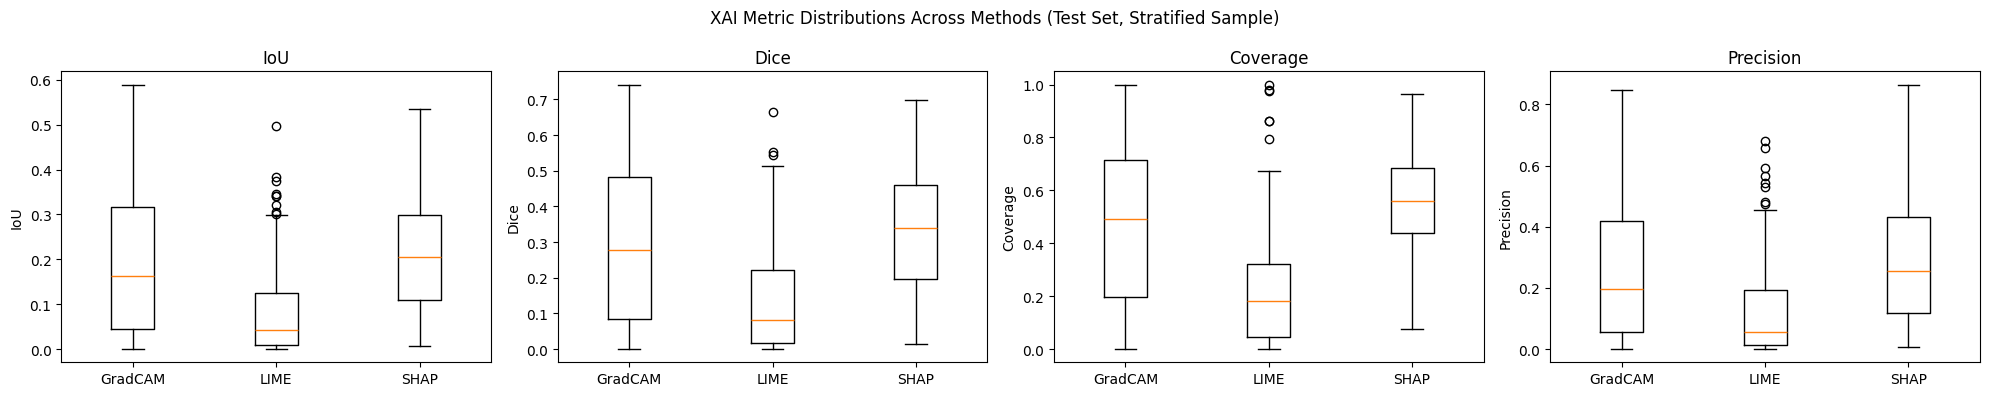

In [ ]:
fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4))
for ax, metric in zip(axes, metrics):
    data = [gt_subset[f"{metric}_{m}"].dropna() for m in methods]
    ax.boxplot(data, labels=methods)
    ax.set_title(metric)
    ax.set_ylabel(metric)
plt.suptitle("XAI Metric Distributions Across Methods (Test Set, Stratified Sample)")
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "xai_metric_boxplots.png"), dpi=150)
plt.show()


In [ ]:
from scipy import stats
from statsmodels.stats.multitest import multipletests


# ============================================================
# STATISTICAL COMPARISON OF XAI METHODS
#
# All comparisons use the paired Wilcoxon signed-rank test.
# Only paired observations that are valid for BOTH methods
# are included in each comparison.
#
# Holm correction is applied across ALL planned valid
# comparisons together.
# ============================================================


def paired_wilcoxon_test(a, b):
    """
    Performs a paired Wilcoxon signed-rank test.

    Only observations where BOTH a and b are finite are used.

    Returns:
        test        : test name
        stat        : Wilcoxon statistic
        p           : raw p-value
        effect_size : matched rank-biserial correlation
        n           : number of valid paired observations
    """

    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)

    # --------------------------------------------------------
    # Keep only paired observations that are finite in BOTH
    # methods.
    # --------------------------------------------------------

    valid_mask = (
        np.isfinite(a)
        &
        np.isfinite(b)
    )

    a_clean = a[valid_mask]
    b_clean = b[valid_mask]

    differences = a_clean - b_clean

    n = len(differences)

    # --------------------------------------------------------
    # Not enough observations
    # --------------------------------------------------------

    if n < 2:
        return {
            "test": "insufficient_data",
            "stat": np.nan,
            "p": np.nan,
            "effect_size": np.nan,
            "n": n
        }

    # --------------------------------------------------------
    # If every paired difference is zero
    # --------------------------------------------------------

    nonzero_differences = differences[
        differences != 0
    ]

    if len(nonzero_differences) == 0:
        return {
            "test": "wilcoxon_signed_rank",
            "stat": 0.0,
            "p": 1.0,
            "effect_size": 0.0,
            "n": n
        }

    # --------------------------------------------------------
    # Wilcoxon signed-rank test
    # --------------------------------------------------------

    try:

        stat, p = stats.wilcoxon(
            a_clean,
            b_clean,
            zero_method="wilcox",
            alternative="two-sided",
            method="auto"
        )

    except ValueError:

        stat = np.nan
        p = np.nan

    # --------------------------------------------------------
    # Matched rank-biserial correlation
    #
    # Positive -> a tends to be larger than b
    # Negative -> a tends to be smaller than b
    # --------------------------------------------------------

        # --------------------------------------------------------
    # True matched rank-biserial correlation
    #
    # Positive -> a tends to be larger than b
    # Negative -> a tends to be smaller than b
    # --------------------------------------------------------

    abs_diff = np.abs(
        nonzero_differences
    )

    ranks = stats.rankdata(
        abs_diff,
        method="average"
    )

    w_plus = ranks[
        nonzero_differences > 0
    ].sum()

    w_minus = ranks[
        nonzero_differences < 0
    ].sum()

    denominator = (
        w_plus +
        w_minus
    )

    if denominator > 0:

        effect_size = (
            w_plus -
            w_minus
        ) / denominator

    else:

        effect_size = 0.0
    return {
        "test": "wilcoxon_signed_rank",
        "stat": stat,
        "p": p,
        "effect_size": effect_size,
        "n": n
    }


# ============================================================
# PLANNED PAIRWISE COMPARISONS
# ============================================================

pairs = [
    ("GradCAM", "LIME"),
    ("GradCAM", "SHAP"),
    ("LIME", "SHAP")
]


# ============================================================
# RUN ALL PLANNED TESTS FIRST
#
# Collect ALL valid p-values before Holm correction.
# ============================================================

stat_rows = []

raw_p_values = []
raw_p_value_indices = []


for metric in metrics:

    for m1, m2 in pairs:

        column_a = f"{metric}_{m1}"
        column_b = f"{metric}_{m2}"

        # ----------------------------------------------------
        # Paired metric values
        # ----------------------------------------------------

        a = gt_subset[column_a].values
        b = gt_subset[column_b].values

        result = paired_wilcoxon_test(
            a,
            b
        )

        row = {
            "Metric": metric,
            "Comparison": f"{m1} vs {m2}",
            "Test": result["test"],
            "n": result["n"],
            "Statistic": result["stat"],
            "Raw_p": result["p"],
            "Holm_corrected_p": np.nan,
            "Significant_after_correction": False,
            "Effect_size": result["effect_size"]
        }

        stat_rows.append(row)

        # ----------------------------------------------------
        # Store valid p-values for global Holm correction
        # ----------------------------------------------------

        if np.isfinite(result["p"]):

            raw_p_value_indices.append(
                len(stat_rows) - 1
            )

            raw_p_values.append(
                result["p"]
            )


# ============================================================
# HOLM MULTIPLE-COMPARISON CORRECTION
#
# Correction is applied across ALL valid planned
# comparisons together.
# ============================================================

if len(raw_p_values) > 0:

    # IMPORTANT:
    # Keep the complete assignment on ONE logical statement.

    reject, corrected_p_values, _, _ = multipletests(
        raw_p_values,
        alpha=CONFIG["alpha"],
        method="holm"
    )

    # --------------------------------------------------------
    # Put corrected p-values back into corresponding rows.
    # --------------------------------------------------------

    for row_index, corrected_p, reject_value in zip(
        raw_p_value_indices,
        corrected_p_values,
        reject
    ):

        stat_rows[row_index][
            "Holm_corrected_p"
        ] = corrected_p

        stat_rows[row_index][
            "Significant_after_correction"
        ] = bool(reject_value)


# ============================================================
# CREATE FINAL STATISTICAL RESULTS TABLE
# ============================================================

stat_results_df = pd.DataFrame(
    stat_rows
)


# ============================================================
# DISPLAY RESULTS
# ============================================================

pd.set_option(
    "display.max_columns",
    None
)

print(
    "\nStatistical comparison of XAI methods:"
)

print(
    stat_results_df.round(4).to_string(
        index=False
    )
)


# ============================================================
# SAVE RESULTS
# ============================================================

statistical_results_path = os.path.join(
    CONFIG["output_dir"],
    "statistical_test_results.csv"
)

stat_results_df.to_csv(
    statistical_results_path,
    index=False
)

print(
    "\nSaved: statistical_test_results.csv"
)

print(
    f"Number of valid Holm-corrected comparisons: "
    f"{len(raw_p_values)}"
)


Statistical comparison of XAI methods:
   Metric      Comparison                 Test   n  Statistic  Raw_p  Holm_corrected_p  Significant_after_correction  Effect_size
      IoU GradCAM vs LIME wilcoxon_signed_rank 150      936.0 0.0000            0.0000                          True       0.8182
      IoU GradCAM vs SHAP wilcoxon_signed_rank 150     4685.0 0.0667            0.0667                         False      -0.1726
      IoU    LIME vs SHAP wilcoxon_signed_rank 150      740.0 0.0000            0.0000                          True      -0.8693
     Dice GradCAM vs LIME wilcoxon_signed_rank 150      974.0 0.0000            0.0000                          True       0.8108
     Dice GradCAM vs SHAP wilcoxon_signed_rank 150     4389.0 0.0169            0.0506                         False      -0.2249
     Dice    LIME vs SHAP wilcoxon_signed_rank 150      648.0 0.0000            0.0000                          True      -0.8856
 Coverage GradCAM vs LIME wilcoxon_signed_rank 150


--- TP example (idx 3473) ---


  0%|          | 0/500 [00:00<?, ?it/s]

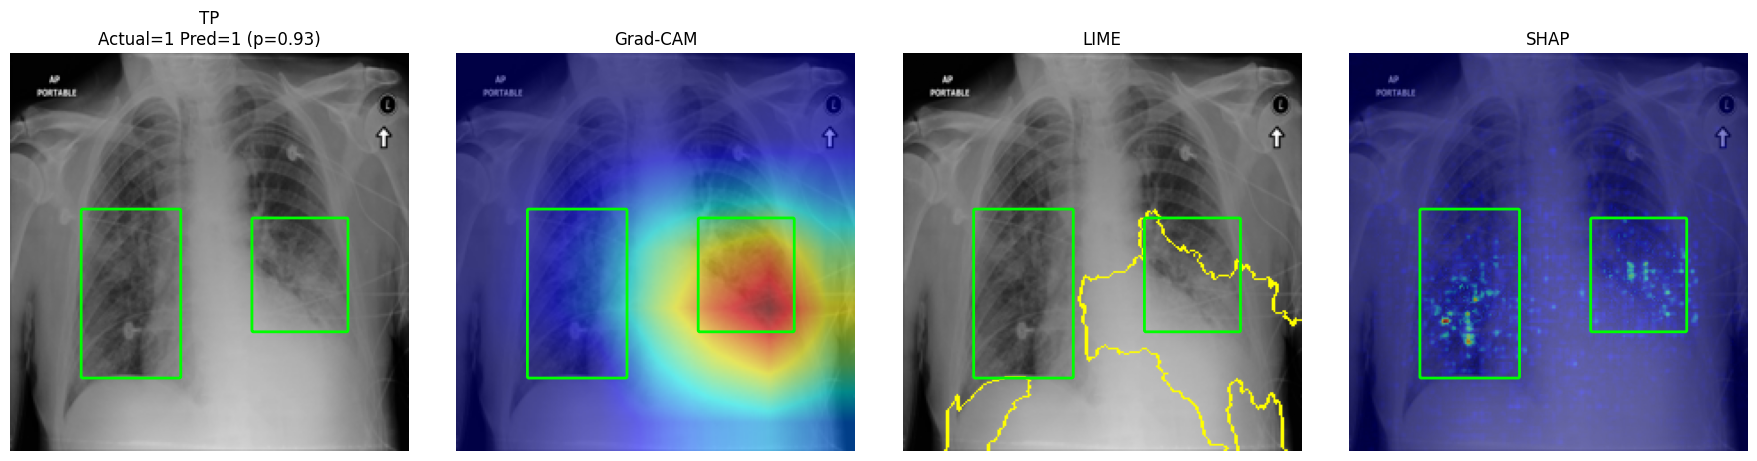

Cautious interpretation only: "the explanation appears to focus on..." / "the highlighted region overlaps with..." — no diagnostic claims are made from any single example.

--- FN example (idx 1821) ---


  0%|          | 0/500 [00:00<?, ?it/s]

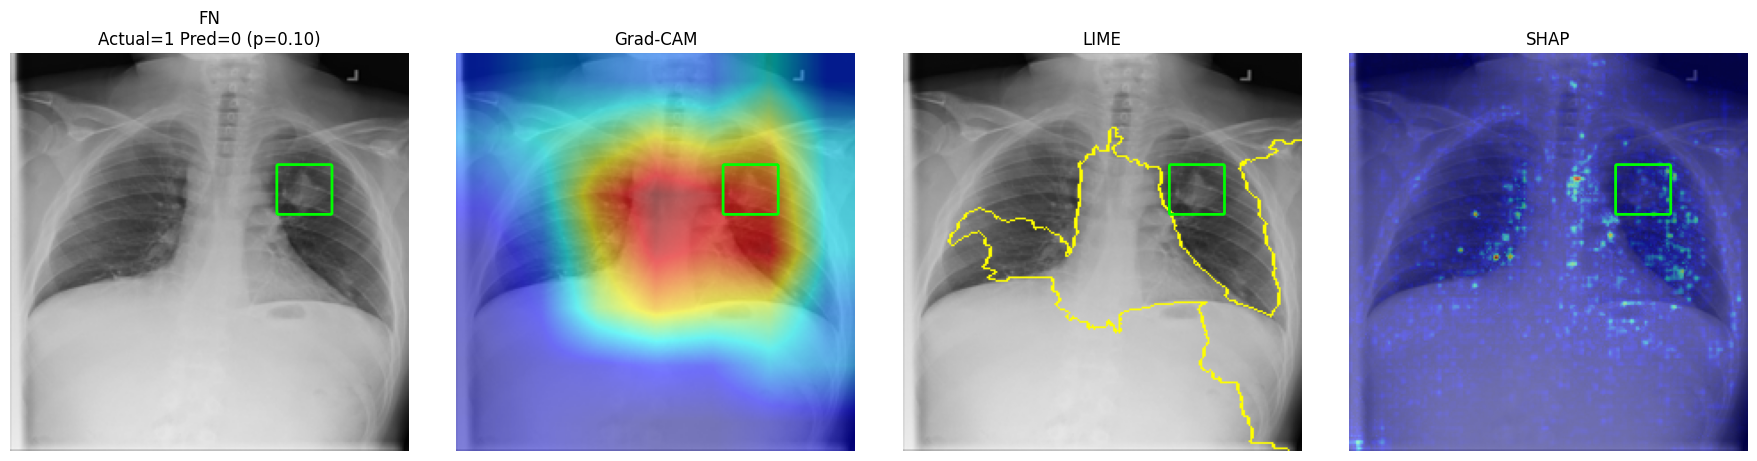

Cautious interpretation only: "the explanation appears to focus on..." / "the highlighted region overlaps with..." — no diagnostic claims are made from any single example.

--- FP example (idx 561) ---


  0%|          | 0/500 [00:00<?, ?it/s]

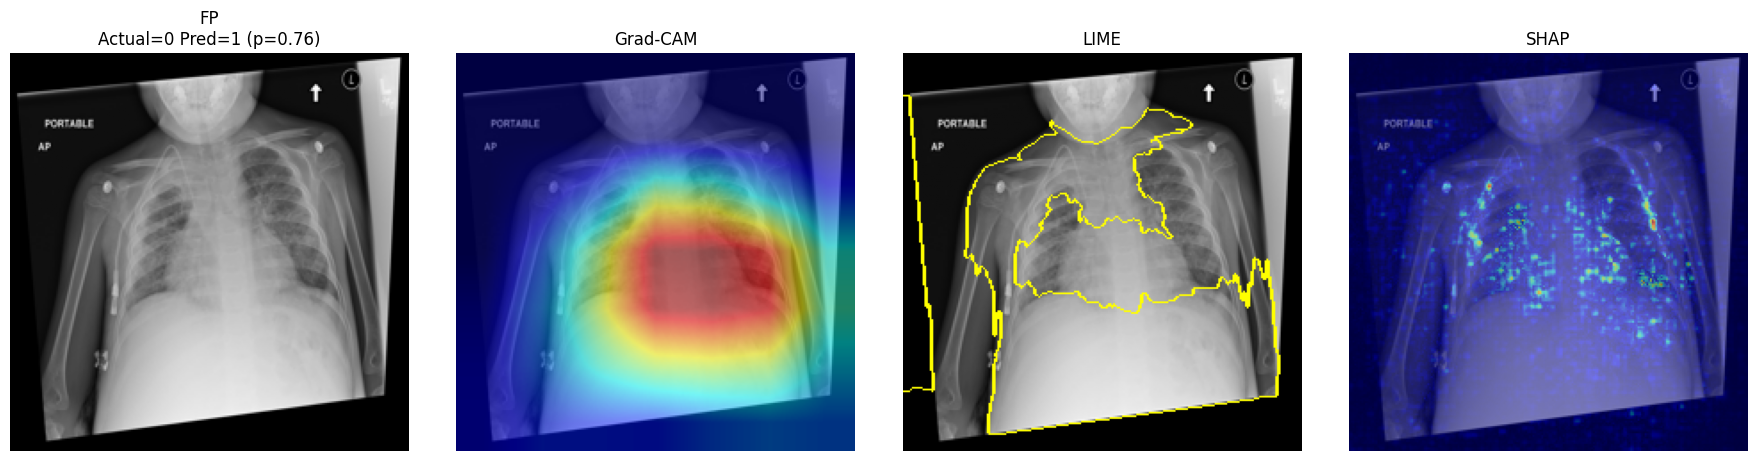

Cautious interpretation only: "the explanation appears to focus on..." / "the highlighted region overlaps with..." — no diagnostic claims are made from any single example.

--- TN example (idx 1897) ---


  0%|          | 0/500 [00:00<?, ?it/s]

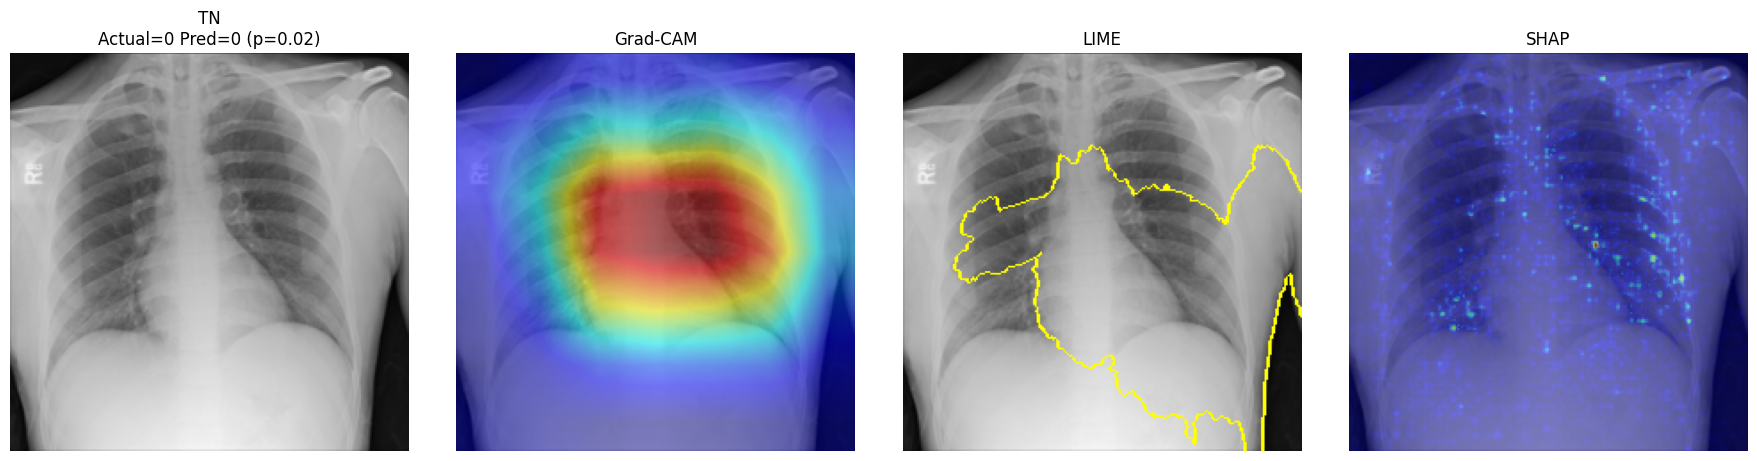

Cautious interpretation only: "the explanation appears to focus on..." / "the highlighted region overlaps with..." — no diagnostic claims are made from any single example.


In [ ]:
def visualize_one_case(idx, outcome_label, title_prefix):
    image_path = test_df_reset.iloc[idx]["image_path"]
    patient_id = test_df_reset.iloc[idx]["patientId"]
    display_image = load_image_for_display(image_path)
    input_tensor = load_input_tensor(image_path)
    predicted_label = int(test_preds_arr[idx])
    predicted_prob = float(test_probs_arr[idx])
    actual_label = int(test_labels_arr[idx])
    gt_mask = get_union_gt_mask(patient_id, raw_boxes_by_patient,
                                 CONFIG["original_dicom_size"], CONFIG["image_size"])

    grayscale_cam = gradcam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(predicted_label)]
)[0]

    cam_image = show_cam_on_image(display_image, grayscale_cam, use_rgb=True)

    lime_overlay, _ = run_lime_explanation(display_image, predicted_label)   # FIX 4
    shap_heatmap = get_shap_heatmap(
    input_tensor,
    predicted_label
    )
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
    axes[0].imshow(display_image)
    if gt_mask.sum() > 0:
        draw_mask_boundary(axes[0], gt_mask)
    axes[0].set_title(f"{title_prefix}\nActual={actual_label} Pred={predicted_label} (p={predicted_prob:.2f})")
    axes[0].axis("off")

    axes[1].imshow(cam_image)
    if gt_mask.sum() > 0:
        draw_mask_boundary(axes[1], gt_mask)
    axes[1].set_title("Grad-CAM"); axes[1].axis("off")

    axes[2].imshow(lime_overlay)
    if gt_mask.sum() > 0:
        draw_mask_boundary(axes[2], gt_mask)
    axes[2].set_title("LIME"); axes[2].axis("off")

    axes[3].imshow(display_image)
    axes[3].imshow(shap_heatmap, cmap="jet", alpha=0.5)
    if gt_mask.sum() > 0:
        draw_mask_boundary(axes[3], gt_mask)
    axes[3].set_title("SHAP"); axes[3].axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(CONFIG["output_dir"], f"failure_analysis_{outcome_label}.png"), dpi=150)
    plt.show()


for outcome_label, pool in [("TP", sample_tp), ("FN", sample_fn), ("FP", sample_fp), ("TN", sample_tn)]:
    if len(pool) == 0:
        print(f"No {outcome_label} cases available in the sampled set — skipping.")
        continue
    example_idx = pool[0]
    print(f"\n--- {outcome_label} example (idx {example_idx}) ---")
    visualize_one_case(example_idx, outcome_label, title_prefix=outcome_label)
    print('Cautious interpretation only: "the explanation appears to focus on..." / '
          '"the highlighted region overlaps with..." — no diagnostic claims are '
          'made from any single example.')

In [ ]:
import os
print("data present:", os.path.exists('/content/rsna_data'))
print("checkpoints:", os.listdir('/content/checkpoints') if os.path.exists('/content/checkpoints') else "none")

data present: True
checkpoints: ['best_model_seed42.pth']


In [ ]:
# ============================================================
# MULTI-SEED REPRODUCIBILITY / SECOND-SEED CHECK
#
# Primary seed:
#     Reuse already-computed primary results.
#
# Additional seed(s):
#     Train only if a valid checkpoint does not already exist.
#     Otherwise, reuse the saved checkpoint.
#
# IMPORTANT:
# - Best epoch is selected using VALIDATION data only.
# - Classification threshold is FROZEN from the primary seed.
# - XAI top-percent is FROZEN from the primary seed.
# - The SAME xai_sample is used for all seeds.
# - Test data is NOT used for tuning.
# - This is a LIMITED reproducibility check.
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget


# ============================================================
# HELPER: TRAIN OR REUSE A SEED MODEL
# ============================================================

def get_seed_model(seed):

    seed_checkpoint = os.path.join(
        CONFIG["checkpoint_dir"],
        f"best_model_seed{seed}.pth"
    )

    seed_metadata_path = os.path.join(
        CONFIG["checkpoint_dir"],
        f"seed{seed}_metadata.json"
    )

    # --------------------------------------------------------
    # Set seed BEFORE model construction/training
    # --------------------------------------------------------

    set_all_seeds(seed)

    seed_model = build_model().to(device)

    # ========================================================
    # REUSE EXISTING CHECKPOINT IF AVAILABLE
    # ========================================================

    if os.path.exists(seed_checkpoint):

        print(
            f"\nCheckpoint found for seed {seed}."
        )

        print(
            f"Reusing checkpoint:\n{seed_checkpoint}"
        )

        try:

            checkpoint_data = torch.load(
                seed_checkpoint,
                map_location=device
            )

            seed_model.load_state_dict(
                checkpoint_data
            )

            seed_model.eval()

            # ------------------------------------------------
            # Recover metadata if available
            # ------------------------------------------------

            seed_best_epoch = np.nan
            seed_best_auc = np.nan

            if os.path.exists(seed_metadata_path):

                try:

                    with open(
                        seed_metadata_path,
                        "r"
                    ) as f:

                        metadata = json.load(f)

                    seed_best_epoch = metadata.get(
                        "best_epoch",
                        np.nan
                    )

                    seed_best_auc = metadata.get(
                        "best_validation_auc",
                        np.nan
                    )

                    print(
                        f"Recovered metadata: "
                        f"best_epoch={seed_best_epoch}, "
                        f"best_validation_auc={seed_best_auc:.4f}"
                        if np.isfinite(seed_best_auc)
                        else
                        f"Recovered metadata: "
                        f"best_epoch={seed_best_epoch}, "
                        f"best_validation_auc=NaN"
                    )

                except Exception as metadata_error:

                    print(
                        "Warning: Could not read seed metadata."
                    )

                    print(
                        f"Reason: {metadata_error}"
                    )

            else:

                print(
                    "No metadata file found for this checkpoint."
                )

                print(
                    "Best epoch and validation AUC will be "
                    "reported as NaN."
                )

            return (
                seed_model,
                seed_best_epoch,
                seed_best_auc,
                seed_checkpoint
            )

        except Exception as checkpoint_error:

            print(
                f"Existing checkpoint for seed {seed} "
                f"could not be loaded."
            )

            print(
                f"Reason: {checkpoint_error}"
            )

            print(
                "A fresh training run will be performed."
            )

    # ========================================================
    # TRAIN FRESH MODEL
    # ========================================================

    print(
        f"\nNo usable checkpoint found for seed {seed}."
    )

    print(
        f"Training fresh model for seed {seed}..."
    )

    seed_optimizer = optim.Adam(
        seed_model.parameters(),
        lr=CONFIG["learning_rate"]
    )

    (
        seed_history,
        seed_best_epoch,
        seed_best_auc
    ) = train_with_early_stopping(
        seed_model,
        train_loader,
        val_loader,
        criterion,
        seed_optimizer,
        device,
        max_epochs=CONFIG["max_epochs"],
        patience=CONFIG["early_stopping_patience"],
        checkpoint_path=seed_checkpoint
    )

    # --------------------------------------------------------
    # Restore BEST validation model
    # --------------------------------------------------------

    seed_model.load_state_dict(
        torch.load(
            seed_checkpoint,
            map_location=device
        )
    )

    seed_model.eval()

    # --------------------------------------------------------
    # Save metadata
    # --------------------------------------------------------

    metadata = {
        "seed": int(seed),
        "best_epoch": int(seed_best_epoch),
        "best_validation_auc": float(seed_best_auc)
    }

    try:

        with open(
            seed_metadata_path,
            "w"
        ) as f:

            json.dump(
                metadata,
                f,
                indent=4
            )

        print(
            f"Saved seed metadata:\n"
            f"{seed_metadata_path}"
        )

    except Exception as metadata_error:

        print(
            f"Warning: Could not save metadata: "
            f"{metadata_error}"
        )

    print(
        f"Fresh training completed for seed {seed}."
    )

    return (
        seed_model,
        seed_best_epoch,
        seed_best_auc,
        seed_checkpoint
    )


# ============================================================
# RUN FULL EVALUATION FOR ONE ADDITIONAL SEED
# ============================================================

def run_full_pipeline_for_seed(seed):

    print(
        "\n=================================================="
    )

    print(
        f"Preparing reproducibility evaluation for seed {seed}"
    )

    print(
        "=================================================="
    )

    # --------------------------------------------------------
    # Obtain trained model
    # --------------------------------------------------------

    (
        seed_model,
        seed_best_epoch,
        seed_best_auc,
        seed_checkpoint
    ) = get_seed_model(seed)

    seed_model.eval()

    # ========================================================
    # TEST-SET CLASSIFICATION
    #
    # IMPORTANT:
    # Use the FROZEN primary-seed classification threshold.
    # ========================================================

    print(
        "\nEvaluating test-set classification..."
    )

    (
        _,
        _,
        _,
        seed_test_labels,
        seed_test_probs
    ) = evaluate_loader(
        seed_model,
        test_loader,
        criterion,
        device
    )

    seed_test_preds = (
        seed_test_probs
        >= CONFIG["classification_threshold"]
    ).astype(int)

    print(
        "Frozen classification threshold:",
        CONFIG["classification_threshold"]
    )

    # ========================================================
    # CLASSIFICATION METRICS
    # ========================================================

    seed_acc = accuracy_score(
        seed_test_labels,
        seed_test_preds
    )

    seed_prec = precision_score(
        seed_test_labels,
        seed_test_preds,
        zero_division=0
    )

    seed_rec = recall_score(
        seed_test_labels,
        seed_test_preds,
        zero_division=0
    )

    seed_f1 = f1_score(
        seed_test_labels,
        seed_test_preds,
        zero_division=0
    )

    seed_cm = confusion_matrix(
        seed_test_labels,
        seed_test_preds,
        labels=[0, 1]
    )

    seed_tn, seed_fp, seed_fn, seed_tp = (
        seed_cm.ravel()
    )

    # --------------------------------------------------------
    # Specificity
    # --------------------------------------------------------

    if (seed_tn + seed_fp) > 0:

        seed_specificity = (
            seed_tn /
            (seed_tn + seed_fp)
        )

    else:

        seed_specificity = np.nan

    # --------------------------------------------------------
    # ROC-AUC
    # --------------------------------------------------------

    try:

        seed_roc_auc = roc_auc_score(
            seed_test_labels,
            seed_test_probs
        )

    except ValueError:

        seed_roc_auc = np.nan

    # ========================================================
    # GRAD-CAM REPRODUCIBILITY
    #
    # Same:
    #   - XAI sample
    #   - frozen top-percent
    #   - ground-truth masks
    #
    # Only the trained model changes.
    # ========================================================

    print(
        "\nRunning Grad-CAM reproducibility evaluation..."
    )

    seed_target_layers = [
        seed_model.layer4[-1]
    ]

    seed_gradcam = GradCAM(
        model=seed_model,
        target_layers=seed_target_layers
    )

    seed_ious = []
    seed_dices = []
    seed_coverages = []
    seed_precisions = []
    seed_pointing_games = []

    total_xai = len(xai_sample)

    # ========================================================
    # SAME XAI SAMPLE
    # ========================================================

    for counter, (idx, outcome) in enumerate(
        xai_sample,
        start=1
    ):

        image_path = (
            test_df_reset
            .iloc[idx]["image_path"]
        )

        patient_id = (
            test_df_reset
            .iloc[idx]["patientId"]
        )

        input_tensor = load_input_tensor(
            image_path
        )

        # ----------------------------------------------------
        # Ground-truth union mask
        # ----------------------------------------------------

        gt_mask = get_union_gt_mask(
            patient_id,
            raw_boxes_by_patient,
            CONFIG["original_dicom_size"],
            CONFIG["image_size"]
        )

        # ----------------------------------------------------
        # Skip cases without localization ground truth
        # ----------------------------------------------------

        if gt_mask.sum() == 0:
            continue

        # ----------------------------------------------------
        # SECOND-SEED PREDICTED CLASS
        # ----------------------------------------------------

        seed_predicted_label = int(
            seed_test_preds[idx]
        )

        # ----------------------------------------------------
        # Grad-CAM
        #
        # Explain the predicted class of THIS seed.
        # ----------------------------------------------------

        cam_map = seed_gradcam(
            input_tensor=input_tensor,
            targets=[
                ClassifierOutputTarget(
                    seed_predicted_label
                )
            ]
        )[0]

        # ----------------------------------------------------
        # FROZEN XAI TOP-PERCENT
        #
        # Do NOT tune this using the test set.
        # ----------------------------------------------------

        pred_mask = heatmap_to_mask_percentile(
            cam_map,
            CONFIG["heatmap_top_percent_final"]
        )

        # ----------------------------------------------------
        # IoU
        # ----------------------------------------------------

        intersection = np.logical_and(
            pred_mask,
            gt_mask
        ).sum()

        union = np.logical_or(
            pred_mask,
            gt_mask
        ).sum()

        if union == 0:
            iou_value = 0.0
        else:
            iou_value = intersection / union

        seed_ious.append(
            iou_value
        )

        # ----------------------------------------------------
        # Areas
        # ----------------------------------------------------

        pred_area = pred_mask.sum()
        gt_area = gt_mask.sum()

        # ----------------------------------------------------
        # Dice
        # ----------------------------------------------------

        dice_denominator = (
            pred_area +
            gt_area
        )

        if dice_denominator == 0:

            dice_value = 0.0

        else:

            dice_value = (
                2.0 *
                intersection /
                dice_denominator
            )

        seed_dices.append(
            dice_value
        )

        # ----------------------------------------------------
        # Coverage
        # ----------------------------------------------------

        if gt_area > 0:

            coverage_value = (
                intersection /
                gt_area
            )

            if np.isfinite(
                coverage_value
            ):

                seed_coverages.append(
                    coverage_value
                )

        # ----------------------------------------------------
        # Region Precision
        # ----------------------------------------------------

        if pred_area > 0:

            precision_value = (
                intersection /
                pred_area
            )

            if np.isfinite(
                precision_value
            ):

                seed_precisions.append(
                    precision_value
                )

        # ----------------------------------------------------
        # Pointing Game
        #
        # Valid here because Grad-CAM is a pixel-level heatmap.
        # ----------------------------------------------------

        max_position = np.unravel_index(
            np.argmax(cam_map),
            cam_map.shape
        )

        pointing_value = int(
            gt_mask[max_position] > 0
        )

        seed_pointing_games.append(
            pointing_value
        )

        # ----------------------------------------------------
        # Progress
        # ----------------------------------------------------

        if counter % 25 == 0:

            print(
                f"Processed "
                f"{counter}/{total_xai} XAI samples..."
            )

    # ========================================================
    # RETURN SEED SUMMARY
    # ========================================================

    return {

        "seed": int(seed),

        "best_epoch": seed_best_epoch,

        "best_validation_auc": seed_best_auc,

        "test_accuracy": seed_acc,

        "test_sensitivity": seed_rec,

        "test_specificity": seed_specificity,

        "test_f1": seed_f1,

        "test_roc_auc": seed_roc_auc,

        "test_precision": seed_prec,

        "gradcam_iou_mean": (
            float(np.mean(seed_ious))
            if seed_ious
            else np.nan
        ),

        "gradcam_iou_std": (
            float(np.std(seed_ious))
            if seed_ious
            else np.nan
        ),

        "gradcam_dice_mean": (
            float(np.mean(seed_dices))
            if seed_dices
            else np.nan
        ),

        "gradcam_dice_std": (
            float(np.std(seed_dices))
            if seed_dices
            else np.nan
        ),

        "gradcam_coverage_mean": (
            float(np.mean(seed_coverages))
            if seed_coverages
            else np.nan
        ),

        "gradcam_precision_mean": (
            float(np.mean(seed_precisions))
            if seed_precisions
            else np.nan
        ),

        "gradcam_pointing_game_mean": (
            float(np.mean(seed_pointing_games))
            if seed_pointing_games
            else np.nan
        ),

        "gradcam_xai_n": len(seed_ious)
    }


# ============================================================
# PRIMARY SEED SUMMARY
#
# Seed 42 is already fully evaluated above.
# Do NOT retrain it here.
# ============================================================

print(
    "\n=================================================="
)

print(
    "Reusing PRIMARY seed results:",
    CONFIG["primary_seed"]
)

print(
    "=================================================="
)


# ------------------------------------------------------------
# Primary Grad-CAM XAI metrics
# ------------------------------------------------------------

primary_iou = gt_subset[
    "IoU_GradCAM"
].dropna()

primary_dice = gt_subset[
    "Dice_GradCAM"
].dropna()

primary_coverage = gt_subset[
    "Coverage_GradCAM"
].dropna()

primary_precision = gt_subset[
    "Precision_GradCAM"
].dropna()

primary_pointing = gt_subset[
    "PointingGame_GradCAM"
].dropna()


# ============================================================
# PRIMARY CLASSIFICATION METRICS
# ============================================================

primary_accuracy = accuracy_score(
    test_labels_arr,
    test_preds_arr
)

primary_precision_value = precision_score(
    test_labels_arr,
    test_preds_arr,
    zero_division=0
)

primary_recall = recall_score(
    test_labels_arr,
    test_preds_arr,
    zero_division=0
)

primary_f1 = f1_score(
    test_labels_arr,
    test_preds_arr,
    zero_division=0
)

primary_cm = confusion_matrix(
    test_labels_arr,
    test_preds_arr,
    labels=[0, 1]
)

primary_tn, primary_fp, primary_fn, primary_tp = (
    primary_cm.ravel()
)

if (primary_tn + primary_fp) > 0:

    primary_specificity = (
        primary_tn /
        (primary_tn + primary_fp)
    )

else:

    primary_specificity = np.nan


try:

    primary_roc_auc = roc_auc_score(
        test_labels_arr,
        test_probs_arr
    )

except ValueError:

    primary_roc_auc = np.nan


# ============================================================
# PRIMARY SEED SUMMARY
# ============================================================

primary_seed_summary = {

    "seed": int(CONFIG["primary_seed"]),

    "best_epoch": best_epoch,

    "best_validation_auc": best_val_auc,

    "test_accuracy": primary_accuracy,

    "test_sensitivity": primary_recall,

    "test_specificity": primary_specificity,

    "test_f1": primary_f1,

    "test_roc_auc": primary_roc_auc,

    "test_precision": primary_precision_value,

    "gradcam_iou_mean": (
        float(primary_iou.mean())
        if len(primary_iou) > 0
        else np.nan
    ),

    "gradcam_iou_std": (
        float(primary_iou.std())
        if len(primary_iou) > 0
        else np.nan
    ),

    "gradcam_dice_mean": (
        float(primary_dice.mean())
        if len(primary_dice) > 0
        else np.nan
    ),

    "gradcam_dice_std": (
        float(primary_dice.std())
        if len(primary_dice) > 0
        else np.nan
    ),

    "gradcam_coverage_mean": (
        float(primary_coverage.mean())
        if len(primary_coverage) > 0
        else np.nan
    ),

    "gradcam_precision_mean": (
        float(primary_precision.mean())
        if len(primary_precision) > 0
        else np.nan
    ),

    "gradcam_pointing_game_mean": (
        float(primary_pointing.mean())
        if len(primary_pointing) > 0
        else np.nan
    ),

    "gradcam_xai_n": len(primary_iou)
}


# ============================================================
# RUN ADDITIONAL REPRODUCIBILITY SEEDS
# ============================================================

extra_seeds = [
    s
    for s in CONFIG["reproducibility_seeds"]
    if s != CONFIG["primary_seed"]
]


seed_summaries = [
    primary_seed_summary
]


for s in extra_seeds:

    print(
        f"\n=== Reproducibility seed {s} ==="
    )

    seed_result = run_full_pipeline_for_seed(
        s
    )

    seed_summaries.append(
        seed_result
    )


# ============================================================
# CREATE MULTI-SEED RESULTS TABLE
# ============================================================

multiseed_df = pd.DataFrame(
    seed_summaries
)


# ============================================================
# DISPLAY PER-SEED RESULTS
# ============================================================

print(
    "\n=================================================="
)

print(
    "PER-SEED REPRODUCIBILITY RESULTS"
)

print(
    "=================================================="
)

print(
    multiseed_df.round(4).to_string(
        index=False
    )
)


# ============================================================
# MEAN ± SD
#
# This is a LIMITED reproducibility summary.
# ============================================================

numeric_cols = [
    c
    for c in multiseed_df.columns
    if c != "seed"
]

mean_row = (
    multiseed_df[numeric_cols]
    .mean(numeric_only=True)
)

std_row = (
    multiseed_df[numeric_cols]
    .std(numeric_only=True)
)


print(
    "\n=================================================="
)

print(
    "MEAN ± SD ACROSS",
    len(seed_summaries),
    "SEED(S)"
)

print(
    "=================================================="
)


for c in numeric_cols:

    mean_value = mean_row[c]
    std_value = std_row[c]

    if np.isfinite(mean_value):

        if np.isfinite(std_value):

            print(
                f"  {c}: "
                f"{mean_value:.4f} ± "
                f"{std_value:.4f}"
            )

        else:

            print(
                f"  {c}: "
                f"{mean_value:.4f} ± NaN"
            )

    else:

        print(
            f"  {c}: NaN"
        )


# ============================================================
# SAVE MULTI-SEED RESULTS
# ============================================================

multiseed_results_path = os.path.join(
    CONFIG["output_dir"],
    "multiseed_results.csv"
)

multiseed_df.to_csv(
    multiseed_results_path,
    index=False
)


# ============================================================
# FINAL STATUS
# ============================================================

print(
    "\n=================================================="
)

print(
    "REPRODUCIBILITY CHECK COMPLETED"
)

print(
    "=================================================="
)

print(
    "Primary seed:",
    CONFIG["primary_seed"]
)

print(
    "Additional seeds evaluated:",
    extra_seeds
)

print(
    "Frozen classification threshold:",
    CONFIG["classification_threshold"]
)

print(
    "Frozen XAI top-percent:",
    CONFIG["heatmap_top_percent_final"]
)

print(
    "XAI sample size:",
    len(xai_sample)
)

print(
    "Saved:",
    multiseed_results_path
)


# ============================================================
# IMPORTANT INTERPRETATION NOTE
# ============================================================

if len(seed_summaries) < 3:

    print(
        f"\nNOTE: This is a LIMITED reproducibility "
        f"check using {len(seed_summaries)} seed(s)."
    )

    print(
        "It should NOT be described as a large-scale "
        "multi-seed robustness study."
    )
else:

    print(
        "\nMultiple seeds were evaluated."
    )


Reusing PRIMARY seed results: 42

=== Reproducibility seed 123 ===

Preparing reproducibility evaluation for seed 123

No usable checkpoint found for seed 123.
Training fresh model for seed 123...
Epoch 1/20 (502.2s) | Train Loss: 0.4956 | Val Loss: 0.4490 | Val Acc: 80.59% | Val AUC: 0.8710  <-- best so far, checkpoint saved
Epoch 2/20 (509.4s) | Train Loss: 0.4453 | Val Loss: 0.4696 | Val Acc: 72.57% | Val AUC: 0.8720  <-- best so far, checkpoint saved
Epoch 3/20 (513.2s) | Train Loss: 0.4152 | Val Loss: 0.4545 | Val Acc: 79.72% | Val AUC: 0.8705
Epoch 4/20 (516.4s) | Train Loss: 0.3873 | Val Loss: 0.4918 | Val Acc: 68.70% | Val AUC: 0.8583
Epoch 5/20 (511.4s) | Train Loss: 0.3466 | Val Loss: 0.4774 | Val Acc: 76.77% | Val AUC: 0.8568
Epoch 6/20 (513.6s) | Train Loss: 0.3074 | Val Loss: 0.5265 | Val Acc: 80.19% | Val AUC: 0.8624
Epoch 7/20 (515.1s) | Train Loss: 0.2510 | Val Loss: 0.5650 | Val Acc: 77.72% | Val AUC: 0.8467

Early stopping: no val-AUC improvement for 5 epochs. Best e

In [ ]:
pd.DataFrame({
    "patientId": test_df_reset["patientId"],
    "true_label": test_labels_arr,
    "predicted_prob": test_probs_arr,
    "predicted_label": test_preds_arr,
}).to_csv(os.path.join(CONFIG["output_dir"], "test_predictions.csv"), index=False)

classification_summary = pd.DataFrame([{
    "Accuracy": acc, "Precision": prec, "Recall_Sensitivity": rec,
    "Specificity": specificity, "F1": f1, "ROC_AUC": roc_auc_test,
    "TP": int(tp), "TN": int(tn), "FP": int(fp), "FN": int(fn),
    "Classification_threshold": CONFIG["classification_threshold"],
}])
classification_summary.to_csv(os.path.join(CONFIG["output_dir"], "classification_summary.csv"), index=False)
print("Classification summary:")
print(classification_summary.round(4).to_string(index=False))

print("\nXAI summary table (mean/median/std/IQR per method per metric): see xai_summary_table.csv")
print("Statistical test results (Holm-corrected): see statistical_test_results.csv")
print("Multi-seed results: see multiseed_results.csv")

with open(os.path.join(CONFIG["output_dir"], "config.json"), "w") as f:
    json.dump(CONFIG, f, indent=2)

print("\nAll artifacts saved under:", CONFIG["output_dir"])
print(os.listdir(CONFIG["output_dir"]))


Classification summary:
 Accuracy  Precision  Recall_Sensitivity  Specificity     F1  ROC_AUC  TP   TN  FP  FN  Classification_threshold
   0.7639     0.4862              0.8392        0.742 0.6157   0.8786 757 2301 800 145                    0.3623

XAI summary table (mean/median/std/IQR per method per metric): see xai_summary_table.csv
Statistical test results (Holm-corrected): see statistical_test_results.csv
Multi-seed results: see multiseed_results.csv

All artifacts saved under: /content/results
['threshold_sensitivity.png', 'statistical_test_results.csv', 'xai_qualitative_grid.png', 'classification_summary.csv', 'xai_results_full.csv', 'confusion_matrix.png', 'config.json', 'multiseed_results.csv', 'training_curves.png', 'failure_analysis_FP.png', 'failure_analysis_TN.png', 'roc_curve.png', 'sanity_check_boxes.png', 'xai_metric_boxplots.png', 'failure_analysis_TP.png', 'failure_analysis_FN.png', 'xai_summary_table.csv', 'test_predictions.csv']


In [ ]:
import os
import shutil

# Your own writable Google Drive location
DRIVE_RESULTS = "/content/drive/MyDrive/Pneumonia_XAI_Final_Run_Results"
DRIVE_CHECKPOINTS = "/content/drive/MyDrive/Pneumonia_XAI_Final_Run_Checkpoints"

os.makedirs(DRIVE_RESULTS, exist_ok=True)
os.makedirs(DRIVE_CHECKPOINTS, exist_ok=True)

# Copy results
for item in os.listdir("/content/results"):
    src = os.path.join("/content/results", item)
    dst = os.path.join(DRIVE_RESULTS, item)

    if os.path.isdir(src):
        shutil.copytree(src, dst, dirs_exist_ok=True)
    else:
        shutil.copy2(src, dst)

# Copy checkpoints
for item in os.listdir("/content/checkpoints"):
    src = os.path.join("/content/checkpoints", item)
    dst = os.path.join(DRIVE_CHECKPOINTS, item)

    if os.path.isfile(src):
        shutil.copy2(src, dst)

print("RESULTS SAVED SUCCESSFULLY")
print("Results:", DRIVE_RESULTS)
print("Checkpoints:", DRIVE_CHECKPOINTS)

print("\nNumber of result files:", len(os.listdir(DRIVE_RESULTS)))
print("Number of checkpoint files:", len(os.listdir(DRIVE_CHECKPOINTS)))

RESULTS SAVED SUCCESSFULLY
Results: /content/drive/MyDrive/Pneumonia_XAI_Final_Run_Results
Checkpoints: /content/drive/MyDrive/Pneumonia_XAI_Final_Run_Checkpoints

Number of result files: 18
Number of checkpoint files: 3


In [ ]:
import os

results_dir = "/content/results"

print("Files produced by the run:\n")

for f in sorted(os.listdir(results_dir)):
    print(f)

Files produced by the run:

classification_summary.csv
config.json
confusion_matrix.png
failure_analysis_FN.png
failure_analysis_FP.png
failure_analysis_TN.png
failure_analysis_TP.png
multiseed_results.csv
roc_curve.png
sanity_check_boxes.png
statistical_test_results.csv
test_predictions.csv
threshold_sensitivity.png
training_curves.png
xai_metric_boxplots.png
xai_qualitative_grid.png
xai_results_full.csv
xai_summary_table.csv


In [ ]:
import pandas as pd

results_dir = "/content/results"

xai_summary = pd.read_csv(
    f"{results_dir}/xai_summary_table.csv"
)

print("XAI Summary:")
display(xai_summary)

XAI Summary:


,Method,IoU_mean,IoU_median,IoU_std,IoU_IQR,Dice_mean,Dice_median,Dice_std,Dice_IQR,Coverage_mean,Coverage_median,Coverage_std,Coverage_IQR,Precision_mean,Precision_median,Precision_std,Precision_IQR
0,GradCAM,0.192726,0.162096,0.156129,0.272504,0.295340,0.278972,0.215489,0.396074,0.475657,0.491718,0.323794,0.518145,0.259634,0.196642,0.230790,0.365235
1,LIME,0.086472,0.042717,0.100985,0.116233,0.145070,0.081934,0.153646,0.204798,0.219534,0.179920,0.220971,0.277349,0.131479,0.056048,0.158616,0.180326
2,SHAP,0.211511,0.204865,0.118350,0.189507,0.333611,0.340023,0.161114,0.263122,0.568236,0.560828,0.172141,0.246051,0.286499,0.254285,0.197674,0.314916


In [ ]:
print("Columns:")
for col in xai_summary.columns:
    print(col)

print("\nFull XAI summary:")
display(xai_summary.T)

Columns:
Method
IoU_mean
IoU_median
IoU_std
IoU_IQR
Dice_mean
Dice_median
Dice_std
Dice_IQR
Coverage_mean
Coverage_median
Coverage_std
Coverage_IQR
Precision_mean
Precision_median
Precision_std
Precision_IQR

Full XAI summary:


,0,1,2
Method,GradCAM,LIME,SHAP
IoU_mean,0.192726,0.086472,0.211511
IoU_median,0.162096,0.042717,0.204865
IoU_std,0.156129,0.100985,0.11835
IoU_IQR,0.272504,0.116233,0.189507
Dice_mean,0.29534,0.14507,0.333611
Dice_median,0.278972,0.081934,0.340023
Dice_std,0.215489,0.153646,0.161114
Dice_IQR,0.396074,0.204798,0.263122
Coverage_mean,0.475657,0.219534,0.568236


In [ ]:
import pandas as pd

stats_path = "/content/results/statistical_test_results.csv"

stats_df = pd.read_csv(stats_path)

print("Statistical test results:")
display(stats_df)

Statistical test results:


,Metric,Comparison,Test,n,Statistic,Raw_p,Holm_corrected_p,Significant_after_correction,Effect_size
0,IoU,GradCAM vs LIME,wilcoxon_signed_rank,150,936.0,2.102802e-17,1.471961e-16,True,0.650350
1,IoU,GradCAM vs SHAP,wilcoxon_signed_rank,150,4685.0,6.665042e-02,6.665042e-02,False,-0.160000
2,IoU,LIME vs SHAP,wilcoxon_signed_rank,150,740.0,2.563898e-20,2.307508e-19,True,-0.813333
3,Dice,GradCAM vs LIME,wilcoxon_signed_rank,150,974.0,4.051745e-17,2.431047e-16,True,0.650350
4,Dice,GradCAM vs SHAP,wilcoxon_signed_rank,150,4389.0,1.687633e-02,5.062900e-02,False,-0.160000
5,Dice,LIME vs SHAP,wilcoxon_signed_rank,150,648.0,5.037327e-21,6.044792e-20,True,-0.813333
6,Coverage,GradCAM vs LIME,wilcoxon_signed_rank,150,1225.0,2.666726e-15,1.333363e-14,True,0.650350
7,Coverage,GradCAM vs SHAP,wilcoxon_signed_rank,150,4199.0,6.034948e-03,2.413979e-02,True,-0.160000
8,Coverage,LIME vs SHAP,wilcoxon_signed_rank,150,654.0,5.606341e-21,6.166975e-20,True,-0.813333
9,Precision,GradCAM vs LIME,wilcoxon_signed_rank,150,918.0,1.538079e-17,1.230463e-16,True,0.650350


In [ ]:
import json

config_path = "/content/results/config.json"

with open(config_path, "r") as f:
    final_config = json.load(f)

print("FINAL CONFIGURATION")
print("=" * 50)

for key, value in final_config.items():
    print(f"{key}: {value}")

FINAL CONFIGURATION
primary_seed: 42
reproducibility_seeds: [42, 123]
data_dir: /content/rsna_data
labels_csv: /content/rsna_data/stage_2_train_labels.csv
images_dir: /content/rsna_data/stage_2_train_images
output_dir: /content/results
checkpoint_dir: /content/checkpoints
image_size: 224
original_dicom_size: 1024
train_frac: 0.7
val_frac: 0.15
test_frac: 0.15
use_horizontal_flip: True
imagenet_mean: [0.485, 0.456, 0.406]
imagenet_std: [0.229, 0.224, 0.225]
model_name: resnet18
batch_size: 32
learning_rate: 0.0001
max_epochs: 20
early_stopping_patience: 5
num_workers: 2
classification_threshold: 0.3623071312904358
xai_target_tp: 100
xai_target_fn: 50
xai_target_fp: 50
xai_target_tn: 50
xai_sampling_seed: 42
gradcam_target_layer: layer4[-1]
gradcam_explanation_target: predicted_class
lime_num_samples: 500
lime_num_features: 5
shap_background_size: 20
shap_channel_reduction: sum_abs
heatmap_top_percent_grid: [2, 5, 10, 15, 20, 30]
heatmap_top_percent_final: 20.0
alpha: 0.05
multiple_compa